# Latent TTA mit Score-Predictor — Plots zu den Aussagen

**Setup.** PMRI, drei Domain Shifts (jeweils Test-Domäne): **3T → 1.5T**, **PROMISE12**, **1.5T → 3T**.
U-Net fest. Ein QC-Head (Score-Predictor) sagt pro Bild eine Beta-Verteilung über den Dice voraus:
Mittelwert **μ̂** („predicted Dice“) und Konzentration **κ** (groß = sicher). Die TTA passt pro Bild
eine kanalweise affine Transformation γ·z + β latenter Features per Gradient Ascent auf μ̂ an,
100 Schritte. Adaptiert wird an zwei Stellen: **Swivel 0** (erster Encoder-Block, 32 Kanäle,
192 × 192) und **Swivel 17** (Decoder, 64 Kanäle, 96 × 96). Das sind pro Bild
2 · (32 + 64) = **192 Parameter** (mit Logit-Affine 194), bei 3.17 Mio. Parametern im U-Net. 5 unabhängig trainierte Score-Predictoren; Kennzahlen sind über
alle Fälle und Predictoren gemittelt.

| Abkürzung | Bedeutung |
|---|---|
| **μ̂-TTA, pre-norm** | Head liest die Features *vor* der InstanceNorm (Setup wie im Paper) |
| **μ̂-TTA, post-norm** | Head liest die Features *nach* der InstanceNorm |
| **Threshold-Oracle (pro Bild)** | keine Adaption; *jedes Bild* bekommt die Logit-Schwelle, die seinen echten Dice maximiert (braucht Labels) |
| **Threshold-Oracle (global)** | keine Adaption; *eine* Schwelle für die ganze Testdomäne, die den mittleren echten Dice maximiert (braucht Labels) |
| **Soft-Dice-Oracle** | dieselbe TTA, aber Gradient Ascent auf den *echten* (weichen) Dice statt auf μ̂ (braucht Labels) |

Alle Oracles sind **Referenzen, keine Methoden**: Sie zeigen, was mit perfekter Information
erreichbar wäre.

**Gliederung**
1. Überblick
2. Pre-norm vs. post-norm
3. Predicted vs. echter Dice
4. κ und Credible Intervals
5. Threshold-Oracle (global und pro Bild): was es ist und wie es zur TTA steht
6. Soft-Dice-Oracle
7. Bei welchen Fällen schadet die TTA?
8. Wann aufhören? (Stopping-Rule)
9. Anhang: Affine auf den Logits

Alle Abbildungen werden zusätzlich als PNG nach `results/plots_treffen_27_10/` geschrieben.

In [1]:
import glob, os, pickle, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

ROOT = os.path.abspath("../../../..")  # repo root
sys.path.insert(0, f"{ROOT}/src")
from model.calibration import beta_credible_interval
from apps.plot_latent_tta import _overlay, _crop_box

FIG_DIR = f"{ROOT}/results/plots_treffen_27_10"
os.makedirs(FIG_DIR, exist_ok=True)

DOMAINS = {"threet-to-onepointfivet": "3T → 1.5T", "promise12": "PROMISE12",
           "onepointfivet-to-threet": "1.5T → 3T"}
PREDICTORS = range(5)
VARIANTS = {   # name -> (results folder, family)
    "pre-norm": ("latent_tta_prenorm", "pre"),
    "post-norm": ("latent_tta_postnorm", "post"),
    "Soft-Dice-Oracle": ("latent_tta_oracle", "oracle"),
    "pre-norm + Logits": ("latent_tta_prenorm_logits", "pre"),
    "post-norm + Logits": ("latent_tta_postnorm_logits", "post"),
    "Soft-Dice-Oracle + Logits": ("latent_tta_oracle_logits", "oracle"),
}
MAIN = ["pre-norm", "post-norm", "Soft-Dice-Oracle"]
LABEL = {"pre-norm": "μ̂-TTA pre-norm", "post-norm": "μ̂-TTA post-norm", "Soft-Dice-Oracle": "Soft-Dice-Oracle"}

# colours: one fixed hue per configuration, references in grey
COL = {"pre-norm": "#2a78d6", "post-norm": "#eb6834", "Soft-Dice-Oracle": "#1baf7a",
       "Threshold-Oracle": "#52514e", "Threshold global": "#52514e", "Ausgang": "#898781"}
GROUP_COL = {"verbessert": "#2a78d6", "unverändert": "#b5b3ad", "geschädigt": "#e34948"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
THR_LS = (0, (1, 1.5))
TOL = 0.05

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.precision", 3)
PCT = plt.matplotlib.ticker.PercentFormatter(1, decimals=0)


def show(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def kappa_axis(ax):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(plt.matplotlib.ticker.LogLocator(subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda y, _: f"{y:g}"))
    ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())

In [2]:
def load(folder, d, p, split="test", with_thr=False):
    path = glob.glob(f"{ROOT}/results/{folder}/pmri_{d}_*cleanHalf_{p}_*/latent_tta.pkl")
    assert len(path) == 1, (folder, d, p)
    with open(path[0], "rb") as f:
        ev = pickle.load(f)["evaluation"][f"{d}_{split}"]
    num = lambda t: t.float().numpy()
    r = {k: num(ev[k]) for k in ("dice_before", "dice_after", "mu_before", "mu_after", "kappa_before",
                                 "kappa_after", "best_dice", "thr_oracle_dice", "thr_global_dice", "logit_drift",
                                 "dice_per_step", "mu_per_step", "kappa_per_step") if k in ev}
    if "thr_oracle_shift" in ev:   # older runs (e.g. 1000 steps) predate the threshold oracle
        r["thr_shift"] = num(ev["thr_oracle_shift"])[:, 0]
        r["thr_global_shift"] = float(ev["thr_global_shift"])
        r["examples"] = {k: v.float().numpy() for k, v in ev["examples"].items()}
    if with_thr:
        r["thr_grid"], r["thr_scores"] = num(ev["thr_grid"]), num(ev["thr_scores"])
    return r


R = {(v, d, p): load(f, d, p, with_thr=(v == "pre-norm" and p == 0))
     for v, (f, _) in VARIANTS.items() for d in DOMAINS for p in PREDICTORS}
for d in DOMAINS:   # every configuration sees the same cases in the same order
    ref = R["pre-norm", d, 0]["dice_before"]
    assert all(np.allclose(R[v, d, p]["dice_before"], ref, atol=1e-4) for v in VARIANTS for p in PREDICTORS)


def pooled(v, d, key):
    return np.concatenate([R[v, d, p][key] for p in PREDICTORS])


def per_pred(v, d, fn):
    return np.array([fn(R[v, d, p]) for p in PREDICTORS])


print({DOMAINS[d]: len(R["pre-norm", d, 0]["dice_before"]) for d in DOMAINS}, "Testfälle je Predictor")

{'3T → 1.5T': 481, 'PROMISE12': 1248, '1.5T → 3T': 1121} Testfälle je Predictor


## 1 · Überblick

**Aussage:** Die μ̂-TTA verbessert den mittleren Dice auf 3T → 1.5T und PROMISE12 deutlich, auf
1.5T → 3T kaum. Das Soft-Dice-Oracle zeigt, dass mit derselben Adaption sehr viel mehr möglich wäre.

*Lesen:* Jeder Punkt ist der mittlere Dice einer Konfiguration; die kleinen Striche sind die 5
Predictoren einzeln. Grau gestrichelt: ohne Adaption; grau gepunktet: Threshold-Oracle pro Bild.
Hohler Kreis: Threshold-Oracle mit *einer* Schwelle für die ganze Domäne.

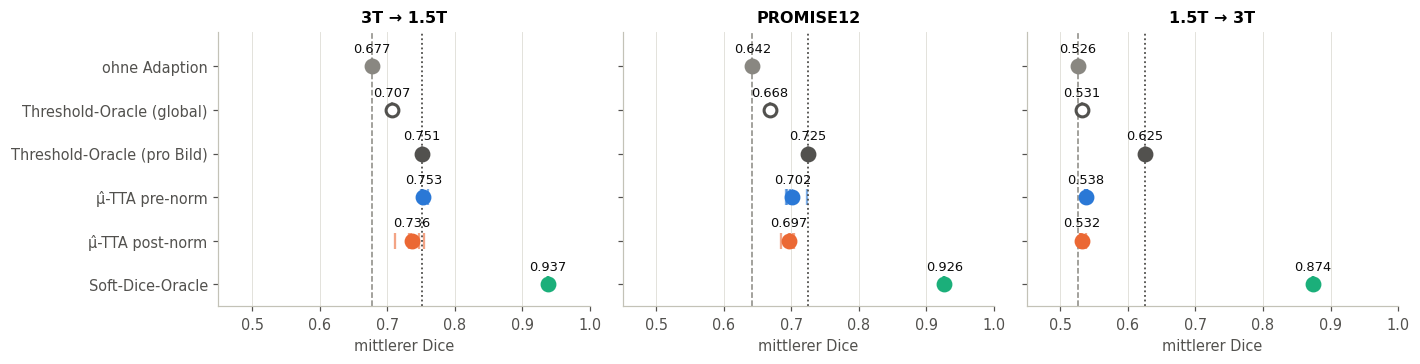

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
rows = ["Ausgang", "Threshold global", "Threshold-Oracle"] + MAIN
NAMES = {"Ausgang": "ohne Adaption", "Threshold global": "Threshold-Oracle (global)",
         "Threshold-Oracle": "Threshold-Oracle (pro Bild)"} | LABEL
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    base = R["pre-norm", d, 0]["dice_before"].mean()
    thr = R["pre-norm", d, 0]["thr_oracle_dice"].mean()
    vals = {"Ausgang": [base], "Threshold-Oracle": [thr], "Threshold global": [R["pre-norm", d, 0]["thr_global_dice"].mean()]}
    vals |= {v: per_pred(v, d, lambda r: r["dice_after"].mean()) for v in MAIN}
    ax.axvline(base, color=COL["Ausgang"], lw=1, ls="--")
    ax.axvline(thr, color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
    for i, name in enumerate(rows):
        x = np.asarray(vals[name])
        ax.scatter(x, np.full(len(x), i), marker="|", s=120, color=COL[name], lw=1.5, alpha=0.6)
        hollow = name == "Threshold global"
        ax.scatter(x.mean(), i, s=70, edgecolor=COL[name], zorder=3, facecolor="white" if hollow else COL[name], lw=2)
        ax.text(x.mean(), i - 0.32, f"{x.mean():.3f}", ha="center", fontsize=8.5, color=INK)
    ax.set_title(dl); ax.set_xlim(0.45, 1.0); ax.set_xlabel("mittlerer Dice")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(rows)), [NAMES[r] for r in rows])
axes[0].set_ylim(len(rows) - 0.5, -0.8)
plt.tight_layout(); show(fig, "01_ueberblick")

Dasselbe als Balkendiagramm. Bei den drei TTA-Varianten zeigt der Fehlerbalken die
Standardabweichung über die 5 Predictoren; die beiden Threshold-Oracles hängen nicht vom
Predictor ab (gleiches U-Net) und haben deshalb keinen.

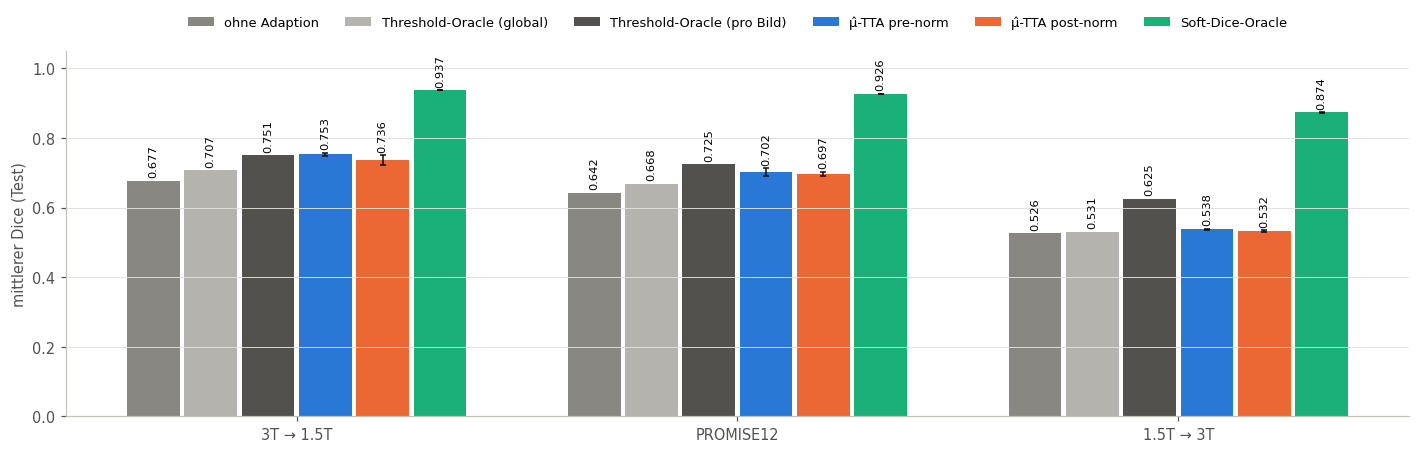

In [4]:
BARS = [("ohne Adaption", "Ausgang", "#898781"), ("Threshold-Oracle (global)", "global", "#b5b3ad"),
        ("Threshold-Oracle (pro Bild)", "image", "#52514e"), ("μ̂-TTA pre-norm", "pre-norm", COL["pre-norm"]),
        ("μ̂-TTA post-norm", "post-norm", COL["post-norm"]), ("Soft-Dice-Oracle", "Soft-Dice-Oracle", COL["Soft-Dice-Oracle"])]
w = 0.13
fig, ax = plt.subplots(figsize=(13, 4.2))
for j, (label, key, c) in enumerate(BARS):
    for i, d in enumerate(DOMAINS):
        r0 = R["pre-norm", d, 0]
        if key == "Ausgang":  m, sd = r0["dice_before"].mean(), None
        elif key == "global": m, sd = r0["thr_global_dice"].mean(), None
        elif key == "image":  m, sd = r0["thr_oracle_dice"].mean(), None
        else:
            x = per_pred(key, d, lambda r: r["dice_after"].mean()); m, sd = x.mean(), x.std()
        xpos = i + (j - (len(BARS) - 1) / 2) * w
        ax.bar(xpos, m, width=w * 0.92, color=c, label=label if i == 0 else None)
        if sd is not None:
            ax.errorbar(xpos, m, yerr=sd, color=INK, lw=1, capsize=2)
        ax.text(xpos, m + (sd or 0) + 0.01, f"{m:.3f}", ha="center", fontsize=7.5, rotation=90, va="bottom")
ax.set_xticks(range(len(DOMAINS)), DOMAINS.values()); ax.set_ylim(0, 1.05)
ax.set_ylabel("mittlerer Dice (Test)"); ax.grid(axis="x", visible=False)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.13), fontsize=8.5)
plt.tight_layout(); show(fig, "01b_ueberblick_balken")

## 2 · Pre-norm vs. post-norm

**Aussage:** Der echte Dice nach der TTA ist mit dem pre-norm-Head in jeder Domäne leicht besser
(+0.017 / +0.005 / +0.006). Der Unterschied ist klein, aber über die 5 Predictoren konsistent.

*Lesen:* links pro Domäne der Dice-Gewinn durch die TTA (ein Punkt pro Predictor, Balken = Mittel).
Rechts der **Logit-Drift**.

**Was ist der Logit-Drift?** Das U-Net gibt pro Pixel einen Logit ℓ aus (die Zahl vor der
Sigmoid); Vordergrund heißt ℓ > 0. Der Logit-Drift eines Bildes ist die mittlere absolute Änderung
dieser Logits durch die Adaption, gemittelt über alle 384 × 384 Pixel:

  Drift = mean over pixels |ℓ_nach − ℓ_vor|

Er misst also, wie stark sich der **Output des U-Nets** tatsächlich verändert hat — unabhängig
davon, was der Head dazu sagt. 0 heißt: Segmentierung unverändert. Zur Einordnung: Die beste
Schwelle pro Bild liegt typischerweise bei t ≈ −4, d. h. eine Verschiebung aller Logits um 4 würde
die Maske deutlich verändern. Ein Drift von 0.5 ist eine kleine, von 2 eine merkliche Änderung.
Da über alle Pixel (auch weit entfernten Hintergrund) gemittelt wird, ist es ein grobes Maß.

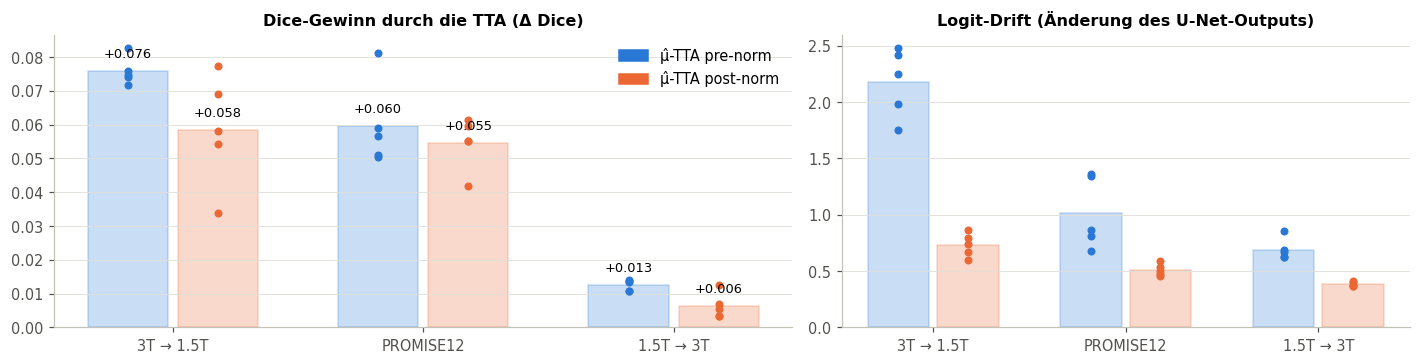

In [5]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(DOMAINS))
for j, v in enumerate(["pre-norm", "post-norm"]):
    for i, d in enumerate(DOMAINS):
        g = per_pred(v, d, lambda r: (r["dice_after"] - r["dice_before"]).mean())
        dr = per_pred(v, d, lambda r: r["logit_drift"].mean())
        off = (j - 0.5) * 0.36
        ax.bar(i + off, g.mean(), width=0.32, color=COL[v], alpha=0.25, edgecolor=COL[v])
        ax.scatter(np.full(5, i + off), g, color=COL[v], s=18, zorder=3)
        ax.text(i + off, g.mean() + 0.004, f"+{g.mean():.3f}", ha="center", fontsize=8.5)
        ax2.bar(i + off, dr.mean(), width=0.32, color=COL[v], alpha=0.25, edgecolor=COL[v])
        ax2.scatter(np.full(5, i + off), dr, color=COL[v], s=18, zorder=3)
for a, t in ((ax, "Dice-Gewinn durch die TTA (Δ Dice)"), (ax2, "Logit-Drift (Änderung des U-Net-Outputs)")):
    a.set_xticks(x, DOMAINS.values()); a.set_title(t); a.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=COL[v], label=LABEL[v]) for v in ["pre-norm", "post-norm"]], loc="upper right")
plt.tight_layout(); show(fig, "02_pre_vs_post")

**Einordnung:** Obwohl der post-norm-Head μ̂ viel stärker hochtreibt (Abschnitt 3), bewegt er den
U-Net-Output 2–3× *weniger*. Er wird also „überzeugt“, ohne dass sich die Segmentierung
entsprechend ändert. Plausible Erklärung: Der post-norm-Head liest genau die Features, die
adaptiert werden, und lässt sich darüber direkt beeinflussen (Hypothese, noch nicht separat getestet).

## 3 · Predicted vs. echter Dice

**Aussage:** Nach der μ̂-TTA wird der Dice in allen Domänen überschätzt, mit dem post-norm-Head
deutlich stärker. Vor der TTA ist der Head auf 3T → 1.5T und PROMISE12 gut kalibriert, auf
1.5T → 3T überschätzt er schon vorher.

### 3.1 Verlauf über die Schritte
*Lesen:* durchgezogen = echter Dice, gestrichelt = μ̂, gemittelt über alle Fälle. Der Abstand
zwischen gleichfarbigen Linien ist die Überschätzung (μ̂ über Dice) bzw. Unterschätzung.

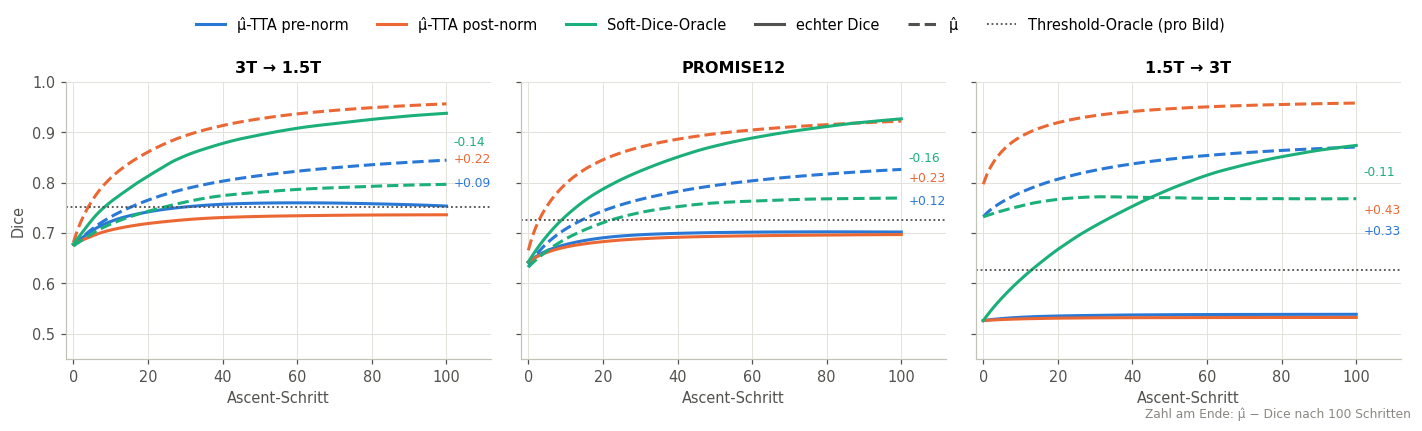

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    labels = []
    for v in MAIN:
        dice, mu = pooled(v, d, "dice_per_step").mean(0), pooled(v, d, "mu_per_step").mean(0)
        ax.plot(dice, color=COL[v]); ax.plot(mu, color=COL[v], ls="--")
        labels.append([(mu[-1] + dice[-1]) / 2, mu[-1] - dice[-1], COL[v]])
    labels.sort(key=lambda l: l[0])
    for a, b in zip(labels, labels[1:]):   # keep end labels at least 0.035 apart
        b[0] = max(b[0], a[0] + 0.035)
    for y, gap, c in labels:
        ax.text(102, y, f"{gap:+.2f}", fontsize=8, color=c, va="center")
    ax.axhline(R["pre-norm", d, 0]["thr_oracle_dice"].mean(), color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
    ax.set_title(dl); ax.set_xlabel("Ascent-Schritt"); ax.set_ylim(0.45, 1.0); ax.set_xlim(-2, 112)
axes[0].set_ylabel("Dice")
handles = [Line2D([], [], color=COL[v], label=LABEL[v]) for v in MAIN]
handles += [Line2D([], [], color=INK2, label="echter Dice"), Line2D([], [], color=INK2, ls="--", label="μ̂"),
            Line2D([], [], color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS, label="Threshold-Oracle (pro Bild)")]
plt.tight_layout(rect=(0, 0, 1, 0.9))
fig.legend(handles=handles, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.0))
fig.text(0.99, 0.01, "Zahl am Ende: μ̂ − Dice nach 100 Schritten", ha="right", fontsize=8, color=MUTED)
show(fig, "03a_verlauf_mu_vs_dice")

### 3.2 Pro Fall: μ̂ gegen echten Dice
*Lesen:* Jeder Punkt ist ein Paar (Fall, Predictor): Jeder Fall erscheint **fünfmal**, einmal pro
Predictor, nicht gemittelt. Vor der TTA haben die fünf Punkte eines Falls denselben echten Dice
(gleiches U-Net) und liegen deshalb senkrecht übereinander; nur μ̂ unterscheidet sich. Nach der
TTA unterscheiden sich beide, weil jeder Predictor seine eigene Adaption steuert.
Auf der Diagonalen wäre μ̂ perfekt.
**Über der Diagonalen = überschätzt**, darunter = unterschätzt. Die Zahl oben links ist die mittlere
Abweichung μ̂ − Dice. Erste Spalte: vor der Adaption (pre-norm-Head).

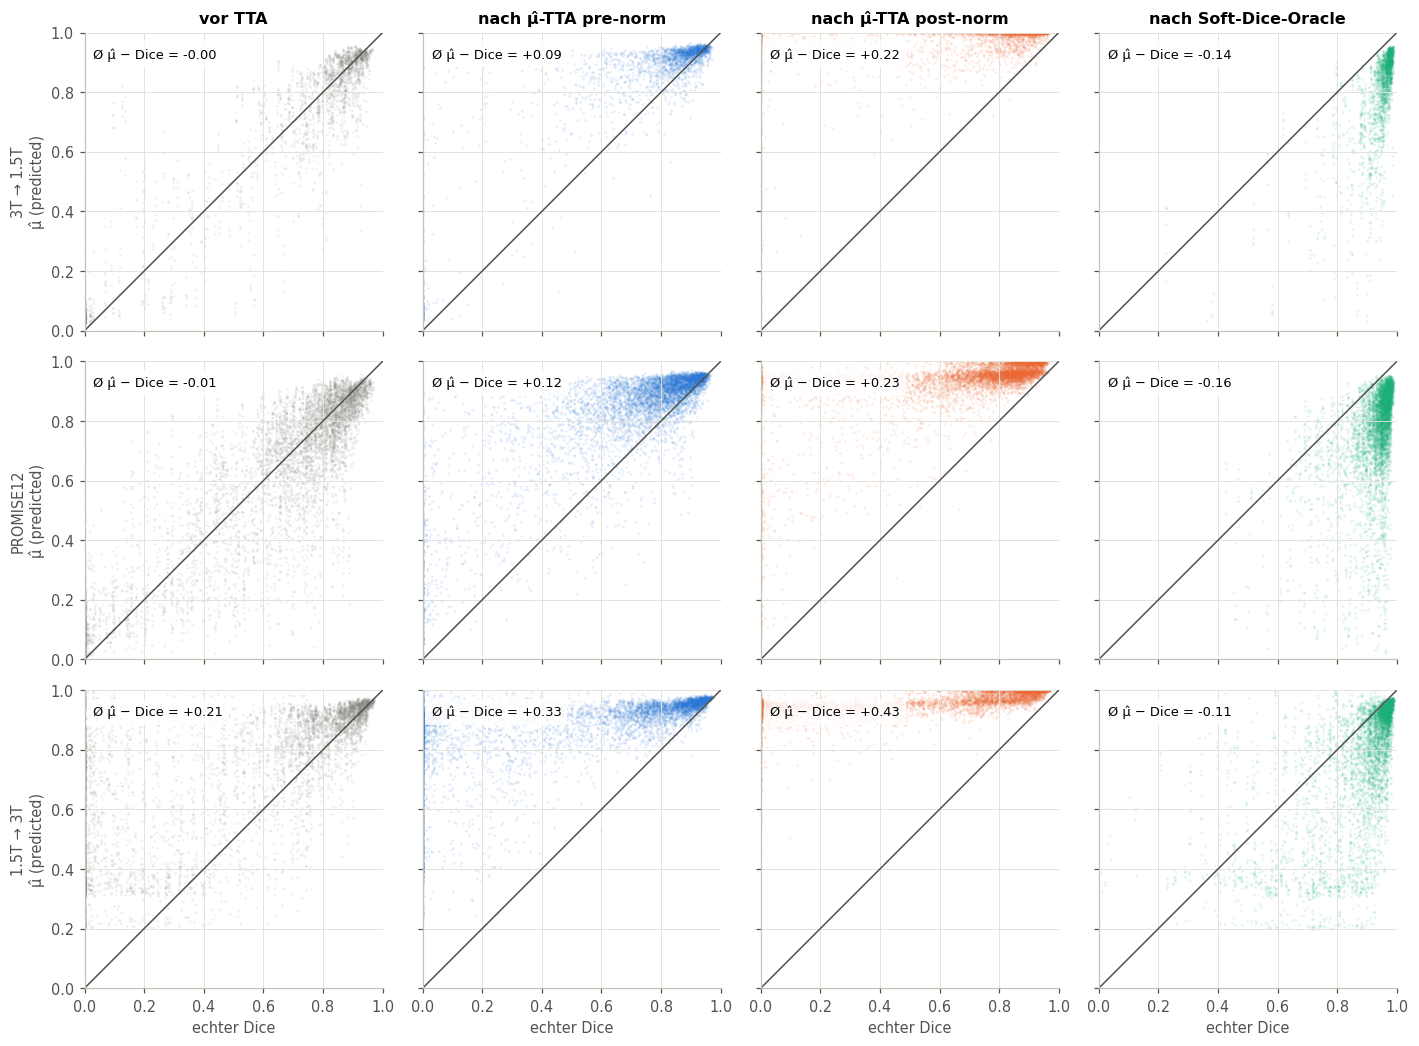

In [7]:
cols = [("vor TTA", "pre-norm", "before"), ("nach μ̂-TTA pre-norm", "pre-norm", "after"),
        ("nach μ̂-TTA post-norm", "post-norm", "after"), ("nach Soft-Dice-Oracle", "Soft-Dice-Oracle", "after")]
fig, axes = plt.subplots(3, 4, figsize=(13, 9.6), sharex=True, sharey=True)
for i, (d, dl) in enumerate(DOMAINS.items()):
    for j, (title, v, when) in enumerate(cols):
        ax = axes[i, j]
        dice, mu = pooled(v, d, f"dice_{when}"), pooled(v, d, f"mu_{when}")
        c = COL[v] if when == "after" else COL["Ausgang"]
        ax.scatter(dice, mu, s=3, alpha=0.12, color=c, lw=0, rasterized=True)
        ax.plot([0, 1], [0, 1], color=INK2, lw=1)
        ax.text(0.03, 0.95, f"Ø μ̂ − Dice = {np.mean(mu - dice):+.2f}", fontsize=8.5, va="top",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        if i == 0: ax.set_title(title)
        if j == 0: ax.set_ylabel(f"{dl}\nμ̂ (predicted)")
        if i == 2: ax.set_xlabel("echter Dice")
plt.tight_layout(); show(fig, "03b_scatter_mu_vs_dice")

**Interpretation**

* **Vor der TTA (grau)** liegt die Wolke auf 3T → 1.5T und PROMISE12 um die Diagonale: μ̂ trifft den
  Dice im Mittel (Abweichung ≈ 0) und ordnet die Fälle gut (Rangkorrelation 0.82–0.85). Auf
  1.5T → 3T liegt sie deutlich darüber (+0.21). Auffällig ist der **senkrechte Streifen bei
  Dice ≈ 0**: 22 % der Fälle sind dort Totalausfälle, und für *alle* davon sagt der Head μ̂ > 0.3,
  meist 0.3–0.9. Der Head erkennt diese Ausfälle nicht.
* **Nach der μ̂-TTA (blau, orange)** wandert die Wolke nach oben und wird oben „plattgedrückt“: μ̂
  landet bei fast allen Fällen bei 0.85–1.0, egal ob der echte Dice 0.3 oder 0.95 ist. Die TTA hat
  also vor allem μ̂ erhöht, nicht den Dice. Damit sinkt auch die Rangkorrelation (z. B. 3T → 1.5T
  0.85 → 0.73). Beim post-norm-Head ist das extrem: Auf 1.5T → 3T liegen praktisch alle μ̂ bei
  ≈ 0.95 (Standardabweichung 0.04), der Head unterscheidet die Fälle kaum noch.
* **Nach dem Soft-Dice-Oracle (grün)** ist es umgekehrt: Die Wolke wandert nach *rechts* (echter
  Dice ≈ 0.9–1.0), μ̂ bleibt breit gestreut (0.2–0.95) und liegt meist *unter* der Diagonalen.
  Der Head unterschätzt die echte Verbesserung: Die Masken werden besser, aber für den Head sehen
  sie nicht so aus.
* **Zusammen:** Der Head reagiert stark auf Veränderungen, die die Maske nicht verbessern, und
  schwach auf solche, die sie verbessern. Das ist der Kern des Problems der μ̂-TTA.

## 4 · κ und Credible Intervals

**Aussage:** Während der μ̂-TTA steigt κ stark an, mit post-norm noch viel stärker. Die
90 %-Intervalle werden schmal und liegen über dem echten Dice: Das Netz überschätzt und ist sich
dabei sehr sicher. Beim Soft-Dice-Oracle bleibt κ fast konstant.

### 4.1 κ über die Schritte
*Lesen:* Die Linie ist der **Median** von κ über alle Fälle (und Predictoren) bei jedem Schritt.
Das **Band** reicht vom 25. bis zum 75. Perzentil: Die Hälfte aller Fälle hat ein κ innerhalb des
Bandes, je ein Viertel liegt darunter bzw. darüber. Es zeigt also die typische Streuung von κ
zwischen den Fällen (y-Achse logarithmisch).

**Was κ bedeutet:** Der Head sagt für jedes Bild eine Beta-Verteilung über den Dice voraus. μ̂ ist
ihr Mittelwert, κ ihre Konzentration. Die Standardabweichung dieser Verteilung ist

  σ = √( μ̂ (1 − μ̂) / (κ + 1) )

Beispiel bei μ̂ = 0.7: Mit κ = 15 ist σ = √(0.21 / 16) ≈ 0.11, der Head sagt also „Dice ungefähr
0.7 ± 0.11“. Mit κ = 500 ist σ = √(0.21 / 501) ≈ 0.02, also „0.7 ± 0.02“ — fast sicher. Je größer κ,
desto schmaler die vorhergesagte Verteilung und desto sicherer ist sich der Head.

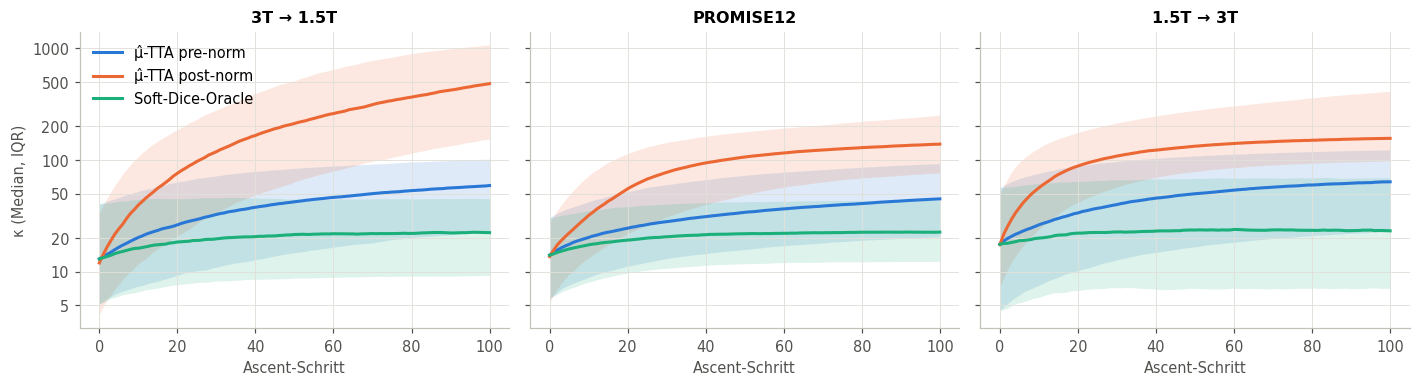

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for v in MAIN:
        K = pooled(v, d, "kappa_per_step")
        q25, q50, q75 = np.percentile(K, [25, 50, 75], axis=0)
        ax.fill_between(np.arange(len(q50)), q25, q75, color=COL[v], alpha=0.15, lw=0)
        ax.plot(q50, color=COL[v], label=LABEL[v])
    kappa_axis(ax); ax.set_title(dl); ax.set_xlabel("Ascent-Schritt")
axes[0].set_ylabel("κ (Median, IQR)"); axes[0].legend(loc="upper left")
plt.tight_layout(); show(fig, "04a_kappa_verlauf")

### 4.2 Die Intervalle einzelner Fälle
**Was ist das Credible Interval?** Aus μ̂ und κ ergibt sich für jedes Bild die vorhergesagte
Beta-Verteilung Beta(α, β) mit α = μ̂ · κ und β = (1 − μ̂) · κ. Das **90 %-Credible-Interval**
ist der Bereich zwischen ihrem 5 %- und ihrem 95 %-Quantil, also der Bereich, in dem der Head den
echten Dice mit 90 % Wahrscheinlichkeit erwartet. Beispiel: μ̂ = 0.7, κ = 15 → Intervall
≈ [0.50, 0.87]; μ̂ = 0.7, κ = 500 → ≈ [0.67, 0.73]. Großes κ macht das Intervall schmal.

Ist der Head gut kalibriert, liegt der echte Dice in etwa 90 % der Fälle im Intervall. Liegt er
viel seltener drin, ist der Head *zu sicher*; liegt er systematisch darunter, *überschätzt* er.

*Lesen:* 30 zufällige Fälle aus 3T → 1.5T (Predictor 0), sortiert nach echtem Dice. Balken =
90 %-Credible-Interval, Kreis = μ̂, **schwarzes Kreuz = echter Dice**. Über jedem Panel der Anteil
dieser 30 Fälle, deren Kreuz im Balken liegt.

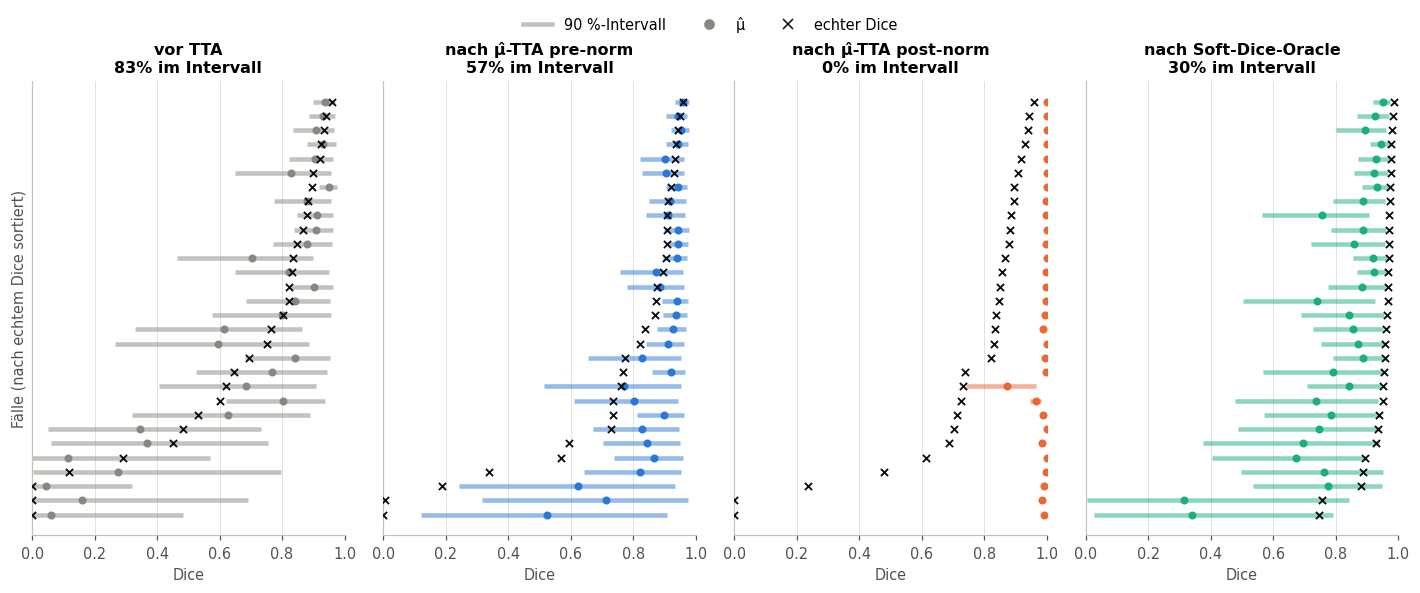

In [9]:
def forest(d="threet-to-onepointfivet", n=30, seed=1):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(R["pre-norm", d, 0]["dice_before"]), n, replace=False)
    panels = [("vor TTA", "pre-norm", "before"), ("nach μ̂-TTA pre-norm", "pre-norm", "after"),
              ("nach μ̂-TTA post-norm", "post-norm", "after"), ("nach Soft-Dice-Oracle", "Soft-Dice-Oracle", "after")]
    fig, axes = plt.subplots(1, 4, figsize=(13, 5.2), sharey=True)
    for ax, (title, v, when) in zip(axes, panels):
        r = R[v, d, 0]
        y, mu, k = r[f"dice_{when}"][idx], r[f"mu_{when}"][idx], r[f"kappa_{when}"][idx]
        lo, hi = beta_credible_interval(mu, k, coverage=0.9)
        order = np.argsort(y); y, mu, lo, hi = y[order], mu[order], lo[order], hi[order]
        c = COL[v] if when == "after" else COL["Ausgang"]
        pos = np.arange(n)
        inside = (y >= lo) & (y <= hi)
        ax.hlines(pos, lo, hi, color=c, lw=3, alpha=0.5)
        ax.scatter(mu, pos, s=18, color=c, zorder=3)
        ax.scatter(y, pos, marker="x", s=22, color=INK, zorder=4, lw=1.2)
        ax.set_title(f"{title}\n{inside.mean():.0%} im Intervall"); ax.set_xlim(0, 1)
        ax.set_xlabel("Dice"); ax.grid(axis="y", visible=False)
    axes[0].set_yticks([]); axes[0].set_ylabel("Fälle (nach echtem Dice sortiert)")
    fig.legend(handles=[Line2D([], [], color=MUTED, lw=3, alpha=0.5, label="90 %-Intervall"),
                        Line2D([], [], color=MUTED, marker="o", ls="", label="μ̂"),
                        Line2D([], [], color=INK, marker="x", ls="", label="echter Dice")],
               loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
    plt.tight_layout(); show(fig, "04b_intervalle_einzelfaelle")


forest()

### 4.3 Über alle Fälle: Breite und Lage der Intervalle

Die Aussage „die Intervalle werden schmal und liegen zu hoch“ in zwei Abbildungen:
erst die **Breite**, dann die **Lage** (wie oft der echte Dice im Intervall liegt und in welche
Richtung er danebenliegt).

*Lesen (Breite):* mittlere Breite des 90 %-Intervalls über alle Fälle und Predictoren. Heller
Balken = vor der TTA, voller Balken = nach der TTA, jeweils mit dem Head der Konfiguration. Kleiner
heißt: Der Head ist sich sicherer.

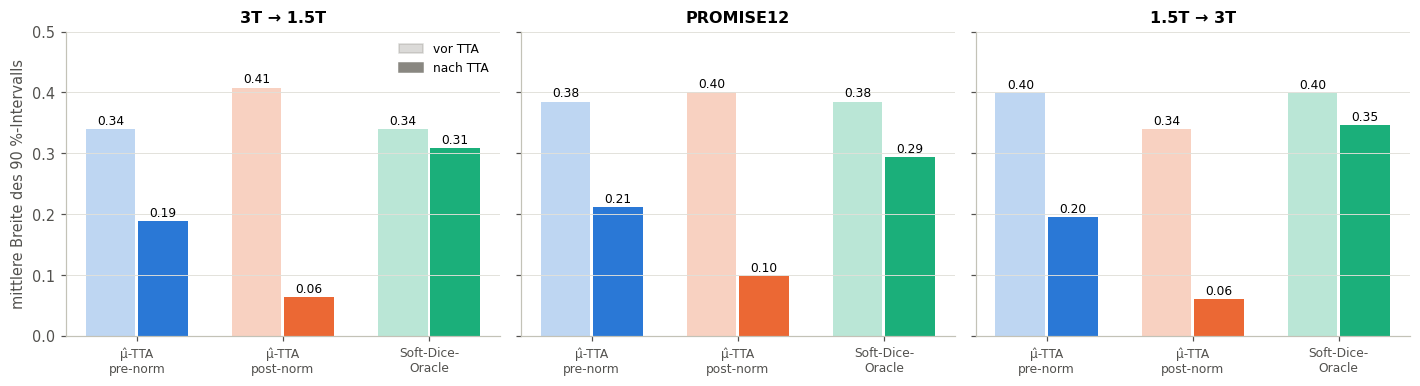

In [10]:
def width(r, when, lvl=0.9):
    lo, hi = beta_credible_interval(r[f"mu_{when}"], r[f"kappa_{when}"], coverage=lvl)
    return (hi - lo).mean()


fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for i, v in enumerate(MAIN):
        before = np.mean([width(R[v, d, p], "before") for p in PREDICTORS])
        after = np.mean([width(R[v, d, p], "after") for p in PREDICTORS])
        ax.bar(i - 0.18, before, width=0.34, color=COL[v], alpha=0.3)
        ax.bar(i + 0.18, after, width=0.34, color=COL[v])
        ax.text(i - 0.18, before + 0.008, f"{before:.2f}", ha="center", fontsize=8)
        ax.text(i + 0.18, after + 0.008, f"{after:.2f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(MAIN)), [LABEL[v].replace("μ̂-TTA ", "μ̂-TTA\n").replace("Soft-Dice-", "Soft-Dice-\n") for v in MAIN],
                  fontsize=8)
    ax.set_title(dl); ax.set_ylim(0, 0.5); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("mittlere Breite des 90 %-Intervalls")
axes[0].legend(handles=[Patch(color=MUTED, alpha=0.3, label="vor TTA"), Patch(color=MUTED, label="nach TTA")],
               loc="upper right", fontsize=8)
plt.tight_layout(); show(fig, "04c_intervallbreite")

**Befund (Breite):** Beim pre-norm-Head halbiert sich die Breite etwa (z. B. 0.34 → 0.19), beim
post-norm-Head schrumpft sie auf 0.06–0.10, also auf ein Viertel bis ein Sechstel. Beim
Soft-Dice-Oracle schrumpft sie nur wenig (um 10–25 %, z. B. 0.34 → 0.31): Dort wird der Head kaum
sicherer, obwohl der Dice tatsächlich stark steigt.

*Lesen (Lage):* Anteil der Fälle, deren echter Dice im 90 %-Intervall liegt (Soll: gestrichelte Linie).
Darunter in welche Richtung die übrigen Fälle danebenliegen: ↓ = echter Dice *unter* dem
Intervall (Intervall liegt zu hoch, Head überschätzt), ↑ = darüber (Head unterschätzt).

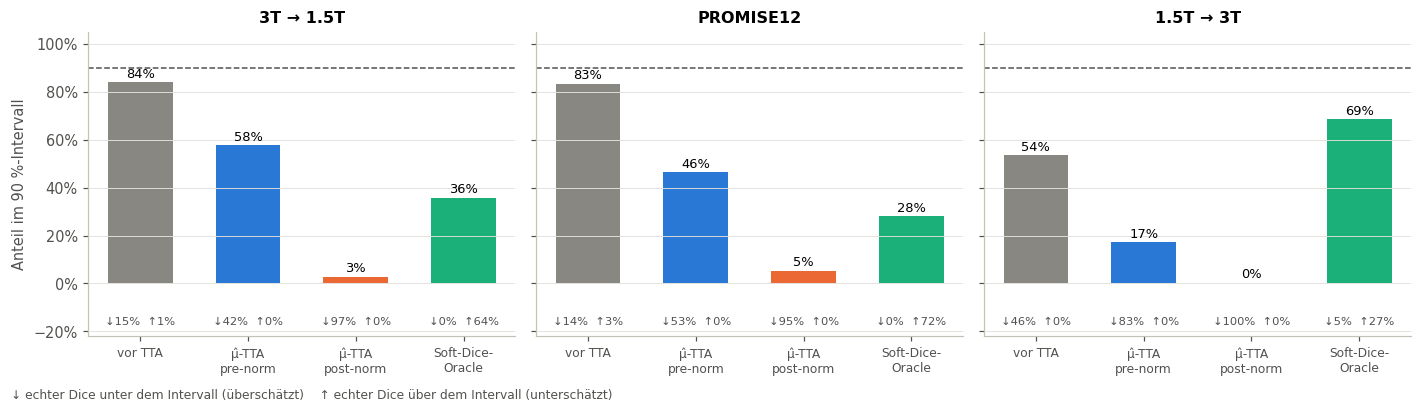

In [11]:
def cov(r, when, lvl=0.9):
    lo, hi = beta_credible_interval(r[f"mu_{when}"], r[f"kappa_{when}"], coverage=lvl)
    y = r[f"dice_{when}"]
    return np.array([((y >= lo) & (y <= hi)).mean(), (y < lo).mean(), (y > hi).mean()])


bars = [("vor TTA", "pre-norm", "before")] + [(LABEL[v], v, "after") for v in MAIN]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for i, (name, v, when) in enumerate(bars):
        c_in, below, above = np.mean([cov(R[v, d, p], when) for p in PREDICTORS], axis=0)
        c = COL[v] if when == "after" else COL["Ausgang"]
        ax.bar(i, c_in, color=c, width=0.6)
        ax.text(i, c_in + 0.02, f"{c_in:.0%}", ha="center", fontsize=8.5)
        ax.text(i, -0.17, f"↓{below:.0%}  ↑{above:.0%}", ha="center", fontsize=7.5, color=INK2)
    ax.axhline(0.9, color=INK2, ls="--", lw=1)
    ax.set_xticks(range(len(bars)), [b[0].replace("μ̂-TTA ", "μ̂-TTA\n").replace("Soft-Dice-", "Soft-Dice-\n") for b in bars], fontsize=8)
    ax.set_title(dl); ax.set_ylim(-0.22, 1.05); ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Anteil im 90 %-Intervall")
fig.text(0.01, -0.02, "↓ echter Dice unter dem Intervall (überschätzt)    ↑ echter Dice über dem Intervall (unterschätzt)",
         fontsize=8, color=INK2)
plt.tight_layout(); show(fig, "04d_coverage")

**Befund (Lage):** Nach der μ̂-TTA liegt der echte Dice fast nur noch *unter* dem Intervall
(pre-norm 42–83 %, post-norm 95–100 % der Fälle), nie darüber. Zusammen mit der Breite: Die
Intervalle werden schmal **und** liegen zu hoch. Der Head überschätzt und ist sich dabei sicher.
Beim Soft-Dice-Oracle ist es umgekehrt: Wenn der echte Dice danebenliegt, dann fast immer *über*
dem Intervall (Head unterschätzt; auf 3T → 1.5T und PROMISE12 bei 64–72 % der Fälle).

## 5 · Threshold-Oracle: was es ist und wie es zur TTA steht

**Was es ist.** Das U-Net gibt pro Pixel einen Logit aus; die Maske ist `Logit > 0`. Das
Threshold-Oracle ändert nichts am Netz, sondern verschiebt nur diese finale Schwelle t. Probiert
werden alle t von −16 bis +16 (Schrittweite 0.1), bewertet mit dem **echten** Dice. Zwei Varianten:

* **pro Bild:** jedes Bild bekommt seine eigene beste Schwelle — ein sehr starkes Oracle, weil
  es für jedes einzelne Bild die Ground Truth braucht;
* **global:** eine einzige Schwelle für die ganze Testdomäne — näher an dem, was man realistisch
  einstellen könnte, aber ebenfalls mit Labels der Zieldomäne gewählt.

Beide sind **Referenzen**: *So gut wird es, wenn man nur die Schwelle verschiebt.* Die TTA kann
mehr (sie verändert die Features), muss es aber ohne Labels schaffen.

### 5.1 An einem Beispiel

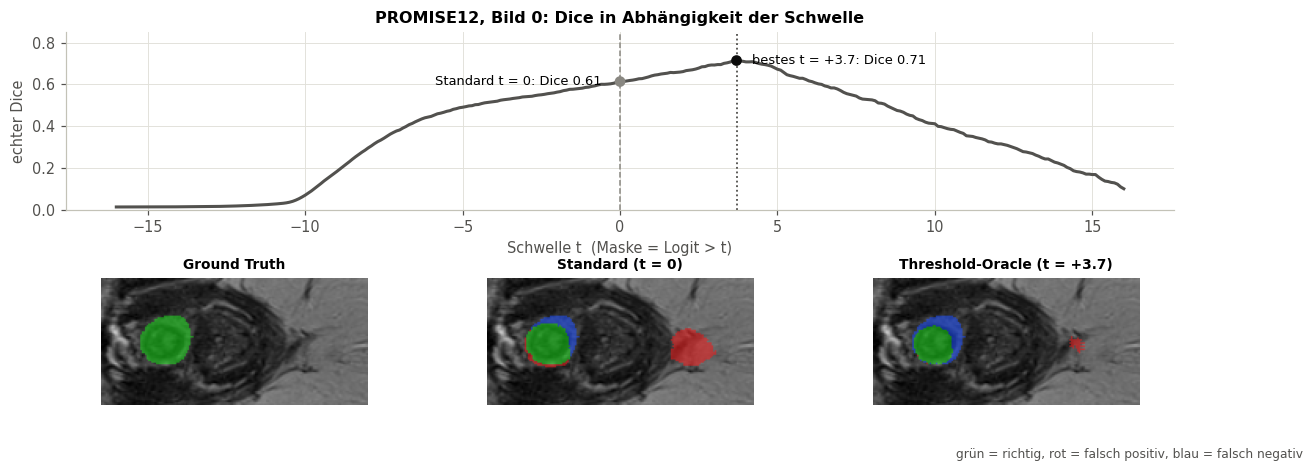

In [12]:
def threshold_example(d="promise12"):
    r = R["pre-norm", d, 0]
    ex = r["examples"]; idx = ex["index"].astype(int)
    gain = r["thr_oracle_dice"][idx] - r["dice_before"][idx]
    k = int(np.argmax(gain)); i = idx[k]
    order = np.argsort(r["thr_grid"]); t, s = r["thr_grid"][order], r["thr_scores"][i][order]
    t_best = r["thr_shift"][i]
    fig = plt.figure(figsize=(13, 4.4))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.4, 1], hspace=0.45, wspace=0.15)
    ax = fig.add_subplot(gs[0, :])
    ax.plot(t, s, color=COL["Threshold-Oracle"])
    ax.axvline(0, color=COL["Ausgang"], ls="--", lw=1)
    ax.axvline(t_best, color=COL["Threshold-Oracle"], ls=THR_LS, lw=1.2)
    ax.scatter([0, t_best], [r["dice_before"][i], r["thr_oracle_dice"][i]], color=[COL["Ausgang"], INK], zorder=3)
    ax.annotate(f"Standard t = 0: Dice {r['dice_before'][i]:.2f}", (0, r["dice_before"][i]), xytext=(-12, 0),
                textcoords="offset points", fontsize=8.5, ha="right", va="center")
    ax.annotate(f"bestes t = {t_best:+.1f}: Dice {r['thr_oracle_dice'][i]:.2f}", (t_best, r["thr_oracle_dice"][i]),
                xytext=(10, 0), textcoords="offset points", fontsize=8.5, va="center")
    ax.set_ylim(0, 0.85)
    ax.set_xlabel("Schwelle t  (Maske = Logit > t)"); ax.set_ylabel("echter Dice")
    ax.set_title(f"{DOMAINS[d]}, Bild {i}: Dice in Abhängigkeit der Schwelle")
    masks = [("Ground Truth", ex["target"][k]), ("Standard (t = 0)", ex["pred_before"][k]),
             (f"Threshold-Oracle (t = {t_best:+.1f})", ex["pred_threshold"][k])]
    ys, xs = _crop_box([m for _, m in masks], ex["target"][k].shape)
    for j, (title, m) in enumerate(masks):
        a = fig.add_subplot(gs[1, j])
        a.imshow(_overlay(ex["image"][k], ex["target"][k], m)[ys, xs]); a.set_title(title, fontsize=9); a.axis("off")
    fig.text(0.99, 0.0, "grün = richtig, rot = falsch positiv, blau = falsch negativ", ha="right", fontsize=8, color=INK2)
    show(fig, "05a_threshold_beispiel")


threshold_example()

### 5.2 Globale Schwelle vs. Schwelle pro Bild vs. μ̂-TTA

**Präzisierung der Aussage „Threshold-Oracle liegt leicht über der TTA“:** Das gilt nur für die
Schwelle *pro Bild*, und auch dann nur auf PROMISE12 (+0.02) und 1.5T → 3T (+0.09); auf
3T → 1.5T liegen beide gleichauf. Gegen die **globale** Schwelle gewinnt die μ̂-TTA in allen drei
Domänen (deutlich auf 3T → 1.5T und PROMISE12, knapp auf 1.5T → 3T).

*Lesen:* Balken = mittlerer Dice. In den Schwellen-Balken die gewählte Schwelle t. Zum Vergleich
steht unter dem Domänennamen die beste globale Schwelle auf der **Quelldomäne** (Validierung):
Dort liegt sie zwischen −0.5 und +1.5, unter dem Shift braucht es t ≈ −4 bis −5. Das Netz segmentiert in der
Zieldomäne also systematisch zu wenig Vordergrund; eine auf der Quelldomäne eingestellte Schwelle
würde nichts bringen.

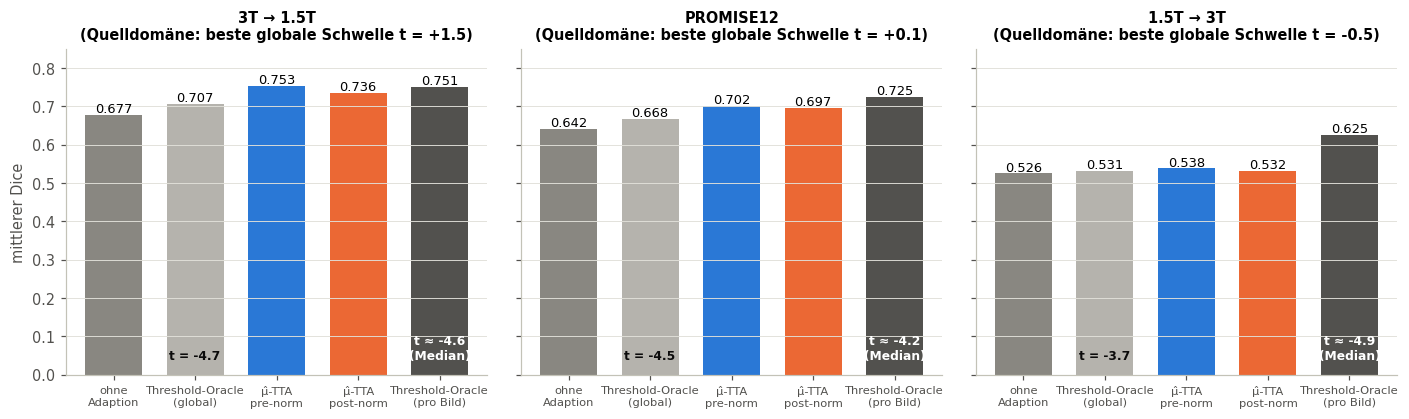

In [13]:
VAL_T = {d: load("latent_tta_prenorm", d, 0, split="val")["thr_global_shift"] for d in DOMAINS}
bars = [("ohne\nAdaption", COL["Ausgang"], None), ("Threshold-Oracle\n(global)", "#b5b3ad", "global"),
        ("μ̂-TTA\npre-norm", COL["pre-norm"], None), ("μ̂-TTA\npost-norm", COL["post-norm"], None),
        ("Threshold-Oracle\n(pro Bild)", COL["Threshold-Oracle"], "image")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    r0 = R["pre-norm", d, 0]
    vals = [r0["dice_before"].mean(), r0["thr_global_dice"].mean(),
            per_pred("pre-norm", d, lambda r: r["dice_after"].mean()).mean(),
            per_pred("post-norm", d, lambda r: r["dice_after"].mean()).mean(), r0["thr_oracle_dice"].mean()]
    for i, ((name, c, kind), v) in enumerate(zip(bars, vals)):
        ax.bar(i, v, color=c, width=0.7)
        ax.text(i, v + 0.006, f"{v:.3f}", ha="center", fontsize=8.5)
        if kind == "global":
            ax.text(i, 0.04, f"t = {r0['thr_global_shift']:+.1f}", ha="center", fontsize=8, color=INK, fontweight="bold")
        if kind == "image":
            ax.text(i, 0.04, f"t ≈ {np.median(r0['thr_shift']):+.1f}\n(Median)", ha="center", fontsize=8,
                    color="white", fontweight="bold")
    ax.set_xticks(range(len(bars)), [b[0] for b in bars], fontsize=7.5)
    ax.set_ylim(0, 0.85); ax.grid(axis="x", visible=False)
    ax.set_title(f"{dl}\n(Quelldomäne: beste globale Schwelle t = {VAL_T[d]:+.1f})", fontsize=9.5)
axes[0].set_ylabel("mittlerer Dice")
plt.tight_layout(); show(fig, "05b_schwellen_global_vs_bild")

### 5.3 Pro Bild: Schwelle vs. μ̂-TTA

Pro Bild ist das Bild gemischt: Die TTA schlägt die beste Schwelle des Bildes bei einem
beträchtlichen Teil der Bilder (dort verändert sie die Maske strukturell), verliert aber bei mehr.

*Lesen:* Ein Punkt pro Bild (pre-norm, alle Predictoren). x = Gewinn des
Threshold-Oracles, y = Gewinn der TTA, jeweils gegenüber ohne Adaption. **Über der Diagonalen ist
die TTA besser als jede Schwellenverschiebung.**

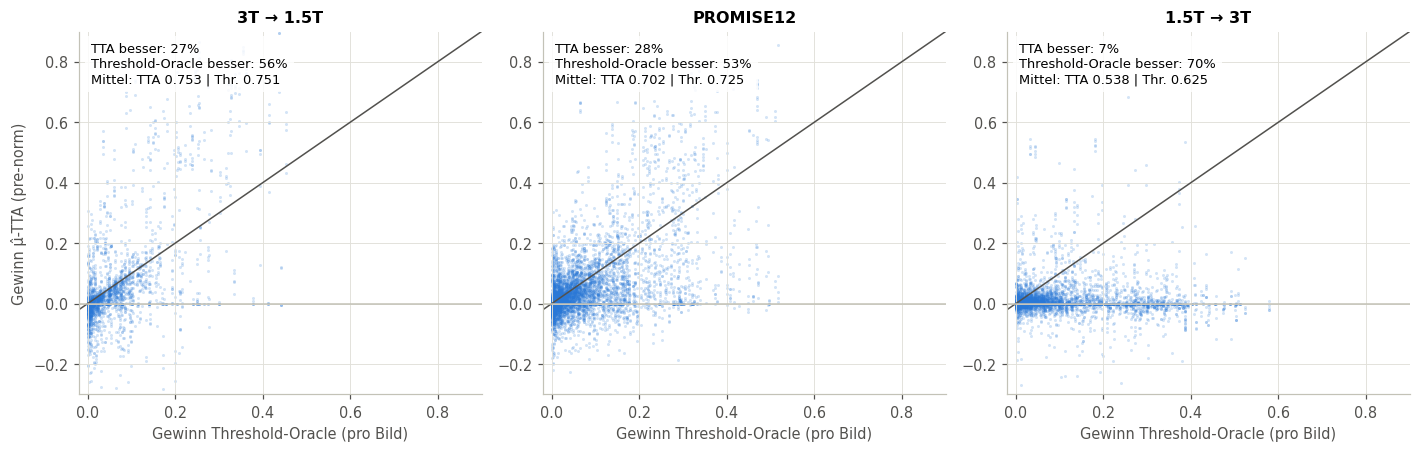

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    b = pooled("pre-norm", d, "dice_before")
    g_thr = pooled("pre-norm", d, "thr_oracle_dice") - b
    g_tta = pooled("pre-norm", d, "dice_after") - b
    ax.scatter(g_thr, g_tta, s=4, alpha=0.2, color=COL["pre-norm"], lw=0, rasterized=True)
    ax.plot([-0.3, 1], [-0.3, 1], color=INK2, lw=1); ax.axhline(0, color=AXIS, lw=1)
    above = (g_tta > g_thr + 0.01).mean(); below = (g_tta < g_thr - 0.01).mean()
    ax.text(0.03, 0.97, f"TTA besser: {above:.0%}\nThreshold-Oracle besser: {below:.0%}\n"
            f"Mittel: TTA {b.mean() + g_tta.mean():.3f} | Thr. {b.mean() + g_thr.mean():.3f}",
            transform=ax.transAxes, va="top", fontsize=8.5, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_xlim(-0.02, 0.9); ax.set_ylim(-0.3, 0.9)
    ax.set_title(dl); ax.set_xlabel("Gewinn Threshold-Oracle (pro Bild)")
axes[0].set_ylabel("Gewinn μ̂-TTA (pre-norm)")
plt.tight_layout(); show(fig, "05c_threshold_vs_tta")

## 6 · Soft-Dice-Oracle

**Aussage:** Wird statt μ̂ der echte (weiche) Dice optimiert, steigt der Dice auf 0.94 / 0.93 / 0.87
(Start 0.68 / 0.64 / 0.53), **und kein einziger Fall wird schlechter**. μ̂ und κ steigen dabei kaum
(Abschnitte 3 und 4): Der Head unterschätzt die echte Verbesserung. Mit einem guten Signal für
den Gradient Ascent kann die Methode also sehr viel erreichen.

### 6.1 Vorher / nachher pro Fall
*Lesen:* Ein Punkt pro Fall. x = Dice vorher, y = Dice nachher. **Über der Diagonalen verbessert,
darunter verschlechtert**; das graue Band markiert ±0.05.

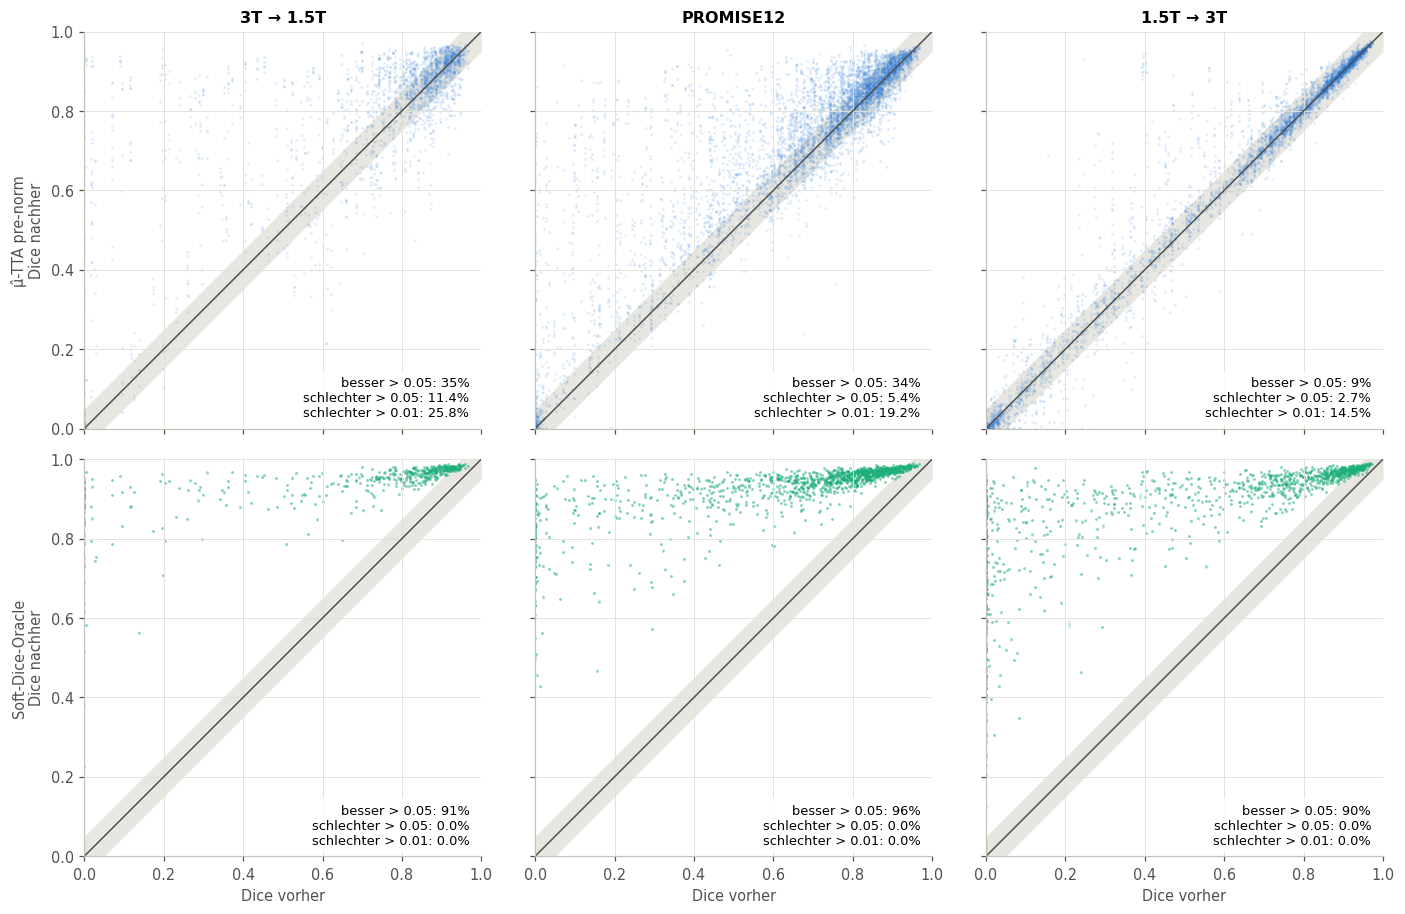

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.4), sharex=True, sharey=True)
for i, v in enumerate(["pre-norm", "Soft-Dice-Oracle"]):
    for j, (d, dl) in enumerate(DOMAINS.items()):
        ax = axes[i, j]
        b, a = pooled(v, d, "dice_before"), pooled(v, d, "dice_after")
        xx = np.linspace(0, 1, 2)
        ax.fill_between(xx, xx - TOL, xx + TOL, color=GRID, alpha=0.8, lw=0)
        ax.scatter(b, a, s=3, alpha=0.15, color=COL[v], lw=0, rasterized=True)
        ax.plot([0, 1], [0, 1], color=INK2, lw=1)
        dd = a - b
        ax.text(0.97, 0.03, f"besser > {TOL}: {(dd > TOL).mean():.0%}\nschlechter > {TOL}: {(dd < -TOL).mean():.1%}\n"
                f"schlechter > 0.01: {(dd < -0.01).mean():.1%}", transform=ax.transAxes, ha="right", fontsize=8.5,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        if i == 0: ax.set_title(dl)
        if j == 0: ax.set_ylabel(f"{LABEL[v]}\nDice nachher")
        if i == 1: ax.set_xlabel("Dice vorher")
plt.tight_layout(); show(fig, "06a_vorher_nachher")

### 6.2 Beispiele
Drei Bilder (Predictor 0) aus den gleichmäßig über die Domäne verteilten Snapshots, automatisch
gewählt (größter Gewinn der μ̂-TTA bzw. stärkste Überschätzung). Oben die Verläufe von echtem Dice
(durchgezogen) und μ̂ (gestrichelt, mit 90 %-Band), unten die Masken.

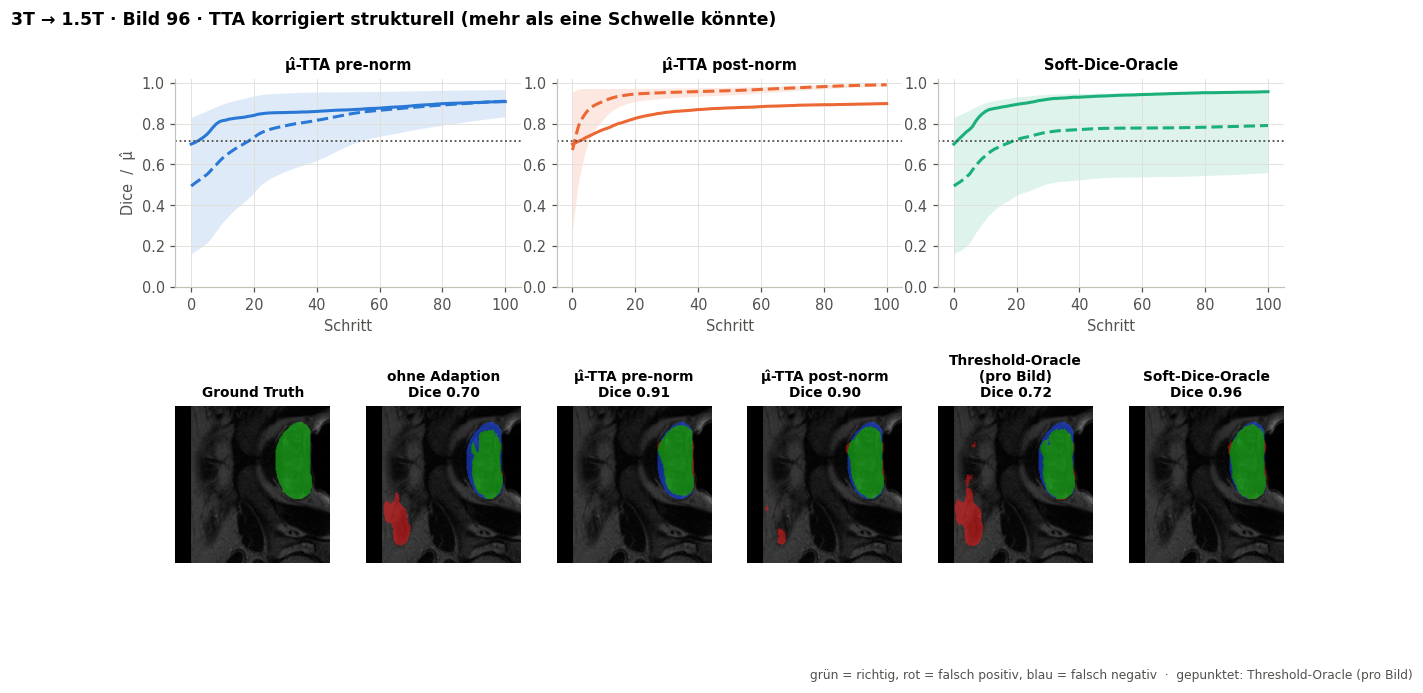

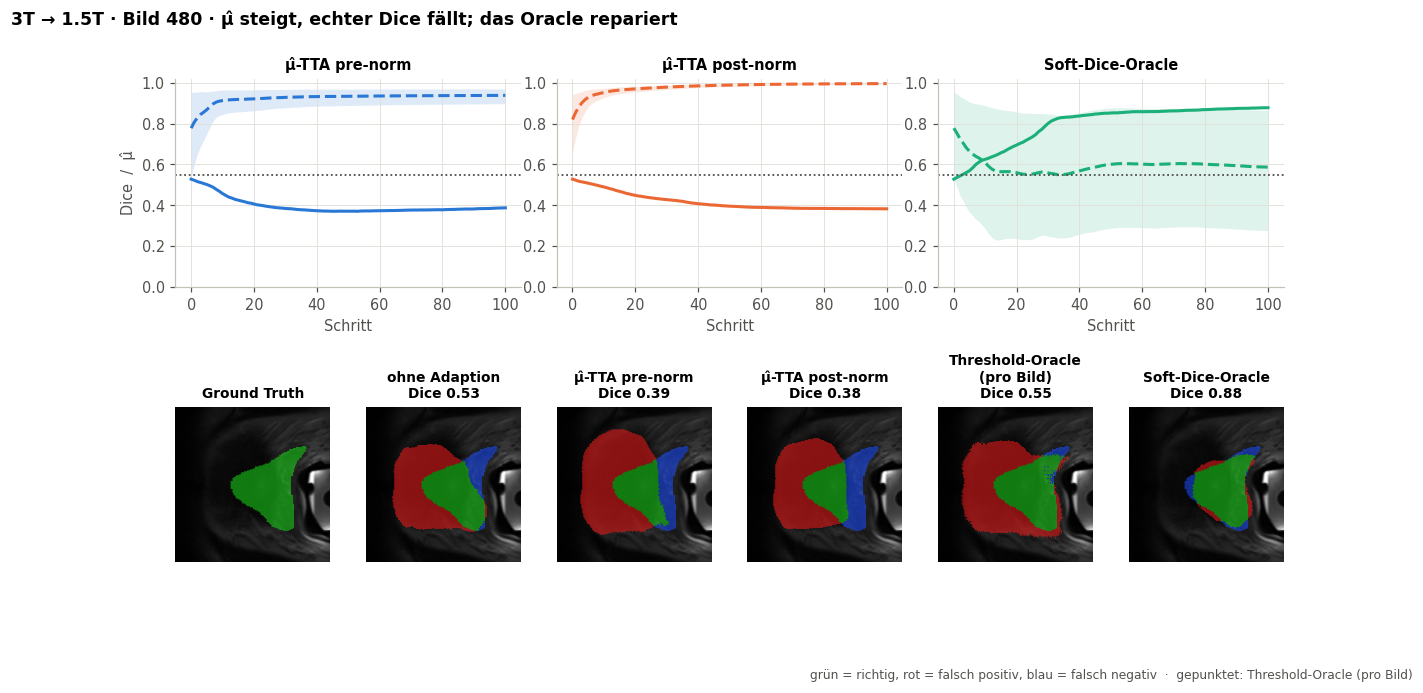

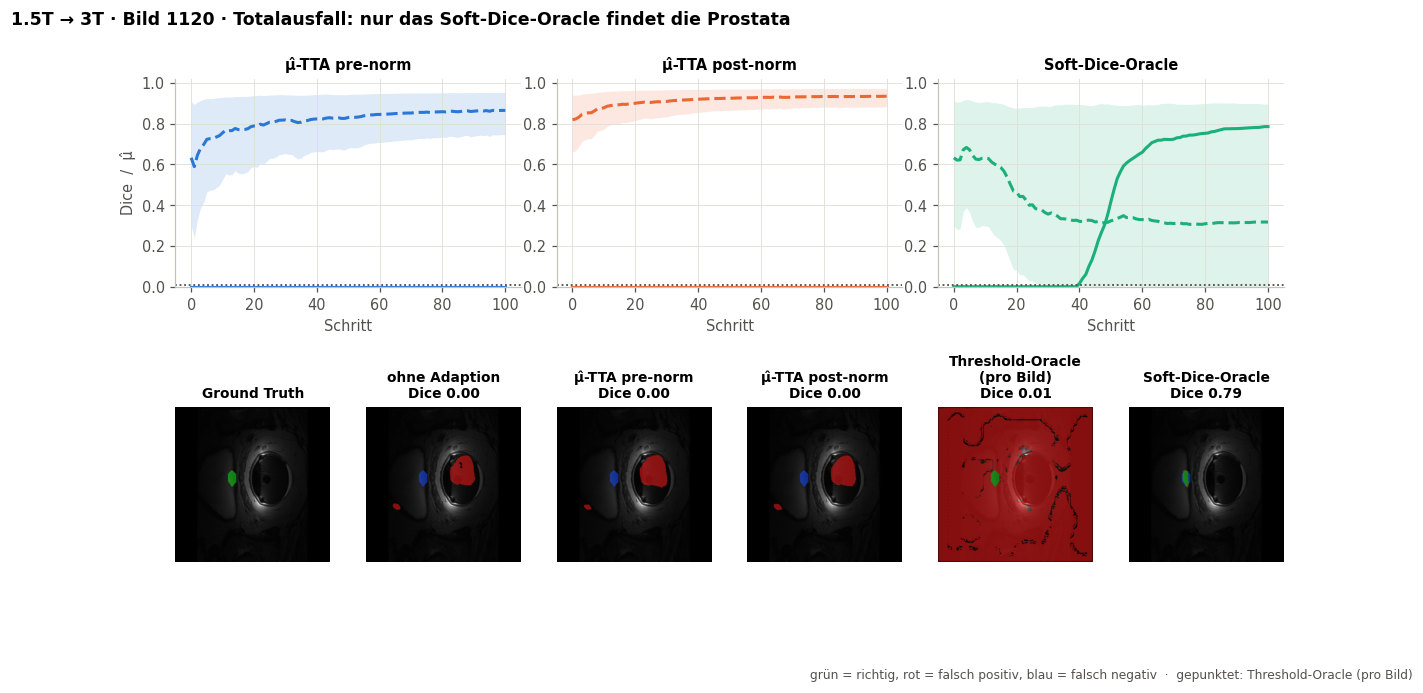

In [16]:
def pick(d, which, p=0):
    ex_idx = R["pre-norm", d, p]["examples"]["index"].astype(int)
    pre, post = R["pre-norm", d, p], R["post-norm", d, p]
    if which == "gain":
        return int(np.argmax(pre["dice_after"][ex_idx] - pre["dice_before"][ex_idx]))
    return int(np.argmax(post["mu_after"][ex_idx] - post["dice_after"][ex_idx]))


def plot_case(d, k, title, name, p=0):
    runs = {v: R[v, d, p] for v in MAIN}
    i = int(runs["pre-norm"]["examples"]["index"][k])
    thr = runs["pre-norm"]["thr_oracle_dice"][i]
    fig = plt.figure(figsize=(13, 6.2))
    gs = fig.add_gridspec(2, 12, height_ratios=[1, 1.15], hspace=0.35, wspace=0.6)
    for j, (v, r) in enumerate(runs.items()):
        ax = fig.add_subplot(gs[0, 4 * j:4 * j + 4])
        dice, mu, kap = r["dice_per_step"][i], r["mu_per_step"][i], r["kappa_per_step"][i]
        lo, hi = beta_credible_interval(mu, kap, coverage=0.9)
        ax.fill_between(np.arange(len(mu)), lo, hi, color=COL[v], alpha=0.15, lw=0)
        ax.plot(dice, color=COL[v]); ax.plot(mu, color=COL[v], ls="--")
        ax.axhline(thr, color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
        ax.set_title(LABEL[v], fontsize=9.5); ax.set_ylim(0, 1.02); ax.set_xlabel("Schritt")
        if j == 0: ax.set_ylabel("Dice  /  μ̂")
    e = runs["pre-norm"]["examples"]
    panels = [("Ground Truth", e["target"][k], None),
              ("ohne Adaption", e["pred_before"][k], runs["pre-norm"]["dice_before"][i]),
              ("μ̂-TTA pre-norm", runs["pre-norm"]["examples"]["pred_final"][k], runs["pre-norm"]["dice_after"][i]),
              ("μ̂-TTA post-norm", runs["post-norm"]["examples"]["pred_final"][k], runs["post-norm"]["dice_after"][i]),
              ("Threshold-Oracle\n(pro Bild)", e["pred_threshold"][k], thr),
              ("Soft-Dice-Oracle", runs["Soft-Dice-Oracle"]["examples"]["pred_final"][k], runs["Soft-Dice-Oracle"]["dice_after"][i])]
    ys, xs = _crop_box([m for _, m, _ in panels], e["target"][k].shape)
    for j, (t, m, dsc) in enumerate(panels):
        ax = fig.add_subplot(gs[1, 2 * j:2 * j + 2])
        ax.imshow(_overlay(e["image"][k], e["target"][k], m)[ys, xs]); ax.axis("off")
        ax.set_title(t + ("" if dsc is None else f"\nDice {dsc:.2f}"), fontsize=9)
    fig.suptitle(f"{DOMAINS[d]} · Bild {i} · {title}", x=0.01, ha="left", fontweight="bold")
    fig.text(0.99, 0.0, "grün = richtig, rot = falsch positiv, blau = falsch negativ  ·  gepunktet: Threshold-Oracle (pro Bild)",
             ha="right", fontsize=8, color=INK2)
    show(fig, name)


plot_case("threet-to-onepointfivet", pick("threet-to-onepointfivet", "gain"),
          "TTA korrigiert strukturell (mehr als eine Schwelle könnte)", "06b_beispiel_gewinn")
plot_case("threet-to-onepointfivet", pick("threet-to-onepointfivet", "over"),
          "μ̂ steigt, echter Dice fällt; das Oracle repariert", "06c_beispiel_ueberschaetzung")
plot_case("onepointfivet-to-threet", pick("onepointfivet-to-threet", "over"),
          "Totalausfall: nur das Soft-Dice-Oracle findet die Prostata", "06d_beispiel_totalausfall")

## 7 · Bei welchen Fällen schadet die TTA?

μ̂-TTA mit pre-norm-Head, 100 Schritte, alle Fälle × 5 Predictoren. **Geschädigt** = Dice am Ende
mehr als 0.05 (bzw. 0.01) unter dem Ausgangswert, **verbessert** = mehr als 0.05 (0.01) darüber.

### 7.1 Nach Ausgangs-Dice
**Aussage (Toleranz 0.05):** Fälle, die schon schlecht starten (< 0.25), werden fast nie geschädigt. Auf
3T → 1.5T und PROMISE12 trifft der Schaden vor allem Fälle ab 0.5, auf 1.5T → 3T dagegen die bei
0.25–0.50. „Gute Fälle werden geschädigt“ stimmt also nur für zwei der drei Domänen.

*Lesen:* Balken = Fälle je Bin des Ausgangs-Dice (Zahl oben = Anzahl Fälle), aufgeteilt in
verbessert / unverändert / geschädigt. Oben mit Toleranz 0.05, unten mit 0.01.

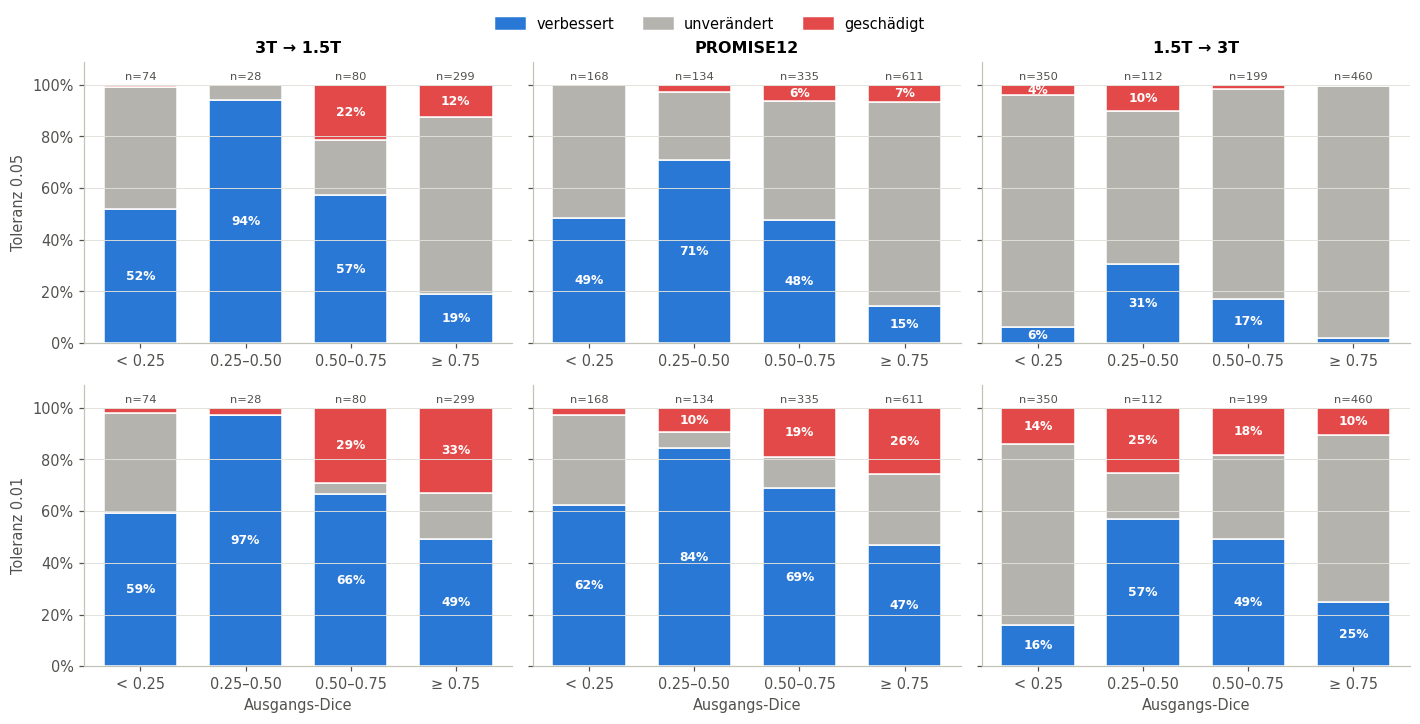

In [17]:
BINS = [(0, .25), (.25, .5), (.5, .75), (.75, 1.01)]
BIN_LABEL = ["< 0.25", "0.25–0.50", "0.50–0.75", "≥ 0.75"]


def groups(v, d, tol, t=-1):
    D = pooled(v, d, "dice_per_step"); delta = D[:, t] - D[:, 0]
    return D[:, 0], np.where(delta > tol, "verbessert", np.where(delta < -tol, "geschädigt", "unverändert"))


fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharey=True)
for i, tol in enumerate([0.05, 0.01]):
    for j, (d, dl) in enumerate(DOMAINS.items()):
        ax = axes[i, j]; b0, g = groups("pre-norm", d, tol)
        for k, (lo, hi) in enumerate(BINS):
            m = (b0 >= lo) & (b0 < hi); bottom = 0
            for name, c in GROUP_COL.items():
                share = (g[m] == name).mean() if m.any() else 0
                ax.bar(k, share, bottom=bottom, color=c, width=0.7, edgecolor="white", lw=1)
                if name != "unverändert" and share >= 0.04:
                    ax.text(k, bottom + share / 2, f"{share:.0%}", ha="center", va="center", fontsize=8,
                            color="white", fontweight="bold")
                bottom += share
            ax.text(k, 1.02, f"n={m.sum() // 5}", ha="center", fontsize=7.5, color=INK2)
        ax.set_xticks(range(4), BIN_LABEL); ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False)
        ax.set_ylim(0, 1.09)
        if i == 0: ax.set_title(dl)
        if i == 1: ax.set_xlabel("Ausgangs-Dice")
        if j == 0: ax.set_ylabel(f"Toleranz {tol}")
fig.legend(handles=[Patch(color=c, label=n) for n, c in GROUP_COL.items()], loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); show(fig, "07a_schaden_nach_ausgangsdice")

### 7.2 Nach Kalibrierung des Heads (μ̂₀ ≠ Dice₀)
**Aussage:** Wie stark μ̂ vorher danebenlag, sagt Schaden allein kaum vorher (AUROC 0.53–0.62).
Die **Richtung** zählt: Bei guten Fällen (≥ 0.75) werden vor allem die geschädigt, die der Head
*unterschätzt* (er hält eine gute Maske für schlecht und verändert sie). Bei mittleren Fällen eher
die überschätzten.

*Lesen:* Innerhalb jedes Bins des Ausgangs-Dice sind die Fälle in drei gleich große Gruppen nach
μ̂₀ − Dice₀ geteilt: unterschätzt / mittel / überschätzt. Balkenhöhe = Anteil geschädigt (Toleranz 0.05).

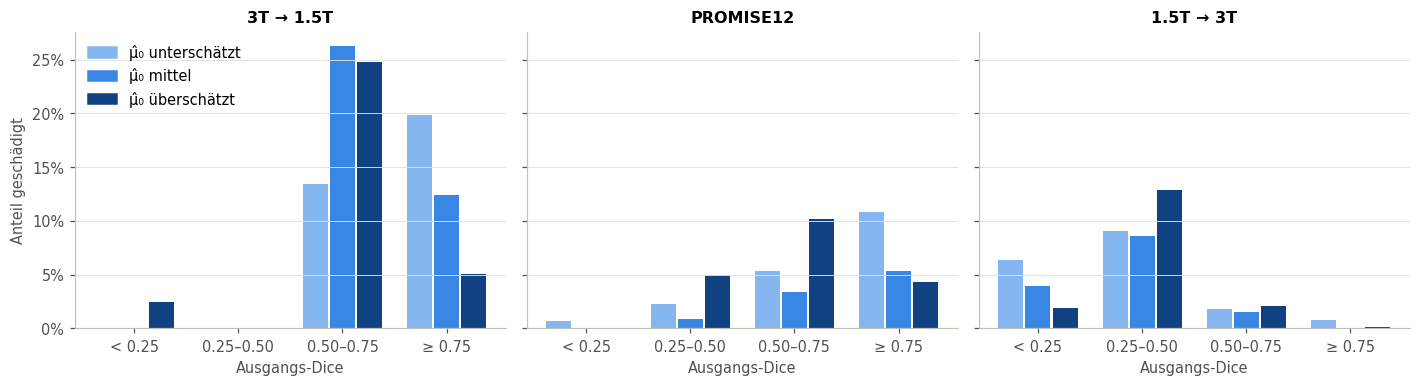

In [18]:
TERC = ["unterschätzt", "mittel", "überschätzt"]
TERC_COL = ["#86b6ef", "#3987e5", "#104281"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    b0, g = groups("pre-norm", d, TOL)
    e0 = pooled("pre-norm", d, "mu_before") - b0
    for k, (lo, hi) in enumerate(BINS):
        m = (b0 >= lo) & (b0 < hi)
        if m.sum() < 50: continue
        q = np.quantile(e0[m], [1 / 3, 2 / 3])
        parts = [m & (e0 <= q[0]), m & (e0 > q[0]) & (e0 <= q[1]), m & (e0 > q[1])]
        for t, (pm, c) in enumerate(zip(parts, TERC_COL)):
            ax.bar(k + (t - 1) * 0.26, (g[pm] == "geschädigt").mean(), width=0.24, color=c)
    ax.set_xticks(range(4), BIN_LABEL); ax.set_title(dl); ax.set_xlabel("Ausgangs-Dice")
    ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Anteil geschädigt")
axes[0].legend(handles=[Patch(color=c, label=f"μ̂₀ {t}") for t, c in zip(TERC, TERC_COL)], loc="upper left")
plt.tight_layout(); show(fig, "07b_schaden_nach_kalibrierung")

### 7.3 Wie Schaden entsteht — und warum der Head ihn nicht bemerkt
**Aussage:** Geschädigte Fälle werden ab dem ersten Schritt schlechter (76–93 % sind zu keinem
Zeitpunkt besser als am Start), während μ̂ für sie trotzdem steigt. Für den Head sieht Schaden aus
wie Erfolg.

*Lesen:* Mittlere Änderung gegenüber dem Start, getrennt nach Endzustand.
Durchgezogen = echter Dice, gestrichelt = μ̂.

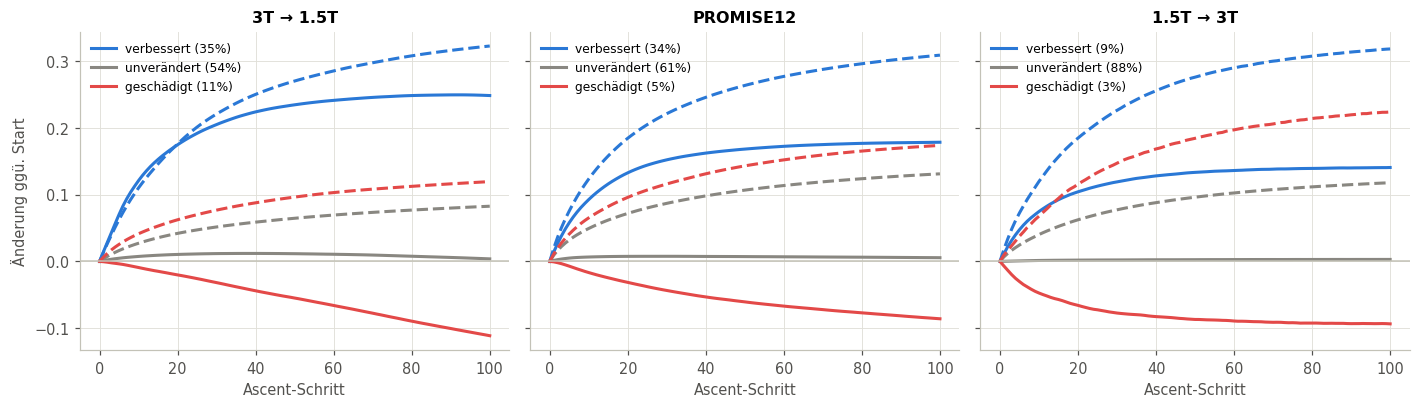

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    D, M = pooled("pre-norm", d, "dice_per_step"), pooled("pre-norm", d, "mu_per_step")
    _, g = groups("pre-norm", d, TOL)
    for name, c in GROUP_COL.items():
        m = g == name
        c = MUTED if name == "unverändert" else c
        ax.plot((D[m] - D[m, :1]).mean(0), color=c, label=f"{name} ({m.mean():.0%})")
        ax.plot((M[m] - M[m, :1]).mean(0), color=c, ls="--")
    ax.axhline(0, color=AXIS, lw=1); ax.set_title(dl); ax.set_xlabel("Ascent-Schritt"); ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Änderung ggü. Start")
plt.tight_layout(); show(fig, "07c_verlauf_nach_gruppe")

## 8 · Wann aufhören?

### 8.1 Der beste Zeitpunkt hängt von der Domäne ab
**Aussage:** Lässt man die TTA lange laufen (1000 Schritte), kippt das Ergebnis auf 3T → 1.5T
ab ~60 Schritten und wird ab ~250 Schritten schlechter als ohne Adaption; auf PROMISE12 liegt das
Optimum bei ~80, auf 1.5T → 3T steigt es bis zum Ende ganz leicht. Eine feste Schrittzahl ist also
domänenabhängig.

*Lesen:* oben mittlerer Dice-Gewinn, unten Anteil geschädigter Fälle; x-Achse logarithmisch.
Punkt = bester Schritt der Domäne.

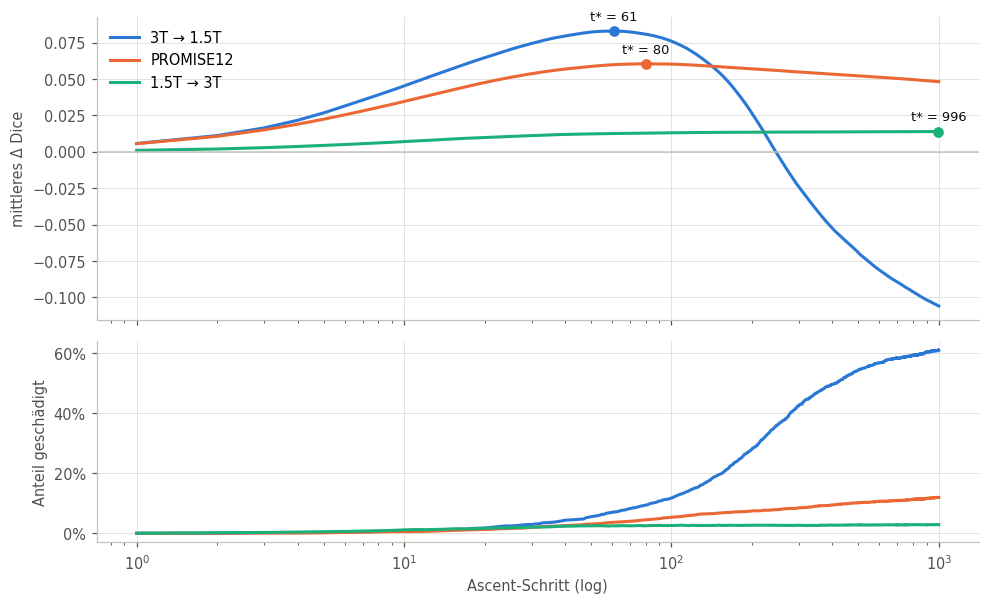

In [20]:
L = {d: {k: np.concatenate([v for v in vs]) for k, vs in zip(
        ["dice_per_step", "mu_per_step", "kappa_before"],
        zip(*[(r["dice_per_step"], r["mu_per_step"], r["kappa_before"])
              for r in (load("latent_tta_1000_steps", d, p) for p in PREDICTORS)]))}
     for d in DOMAINS}
DOM_COL = {"threet-to-onepointfivet": "#2a78d6", "promise12": "#eb6834", "onepointfivet-to-threet": "#1baf7a"}

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
for d, dl in DOMAINS.items():
    D = L[d]["dice_per_step"]; s = np.arange(1, D.shape[1])
    gain = (D[:, 1:] - D[:, :1]).mean(0); harm = (D[:, 1:] < D[:, :1] - TOL).mean(0)
    ax.plot(s, gain, color=DOM_COL[d], label=dl); ax2.plot(s, harm, color=DOM_COL[d])
    t = gain.argmax(); ax.scatter(s[t], gain[t], color=DOM_COL[d], zorder=3)
    ax.annotate(f"t* = {s[t]}", (s[t], gain[t]), xytext=(0, 7), textcoords="offset points", ha="center",
                fontsize=8.5, color=INK)
ax.axhline(0, color=AXIS, lw=1); ax.set_xscale("log"); ax.set_ylabel("mittleres Δ Dice"); ax.legend()
ax2.set_ylabel("Anteil geschädigt"); ax2.yaxis.set_major_formatter(PCT); ax2.set_xlabel("Ascent-Schritt (log)")
plt.tight_layout(); show(fig, "08a_optimum_je_domaene")

### 8.2 Vergleich label-freier Stopping-Rules
Alle Regeln entscheiden **pro Fall** und ohne Labels, simuliert auf den 1000-Schritt-Verläufen:

* **feste Schrittzahl T** (bisher),
* **μ̂-Plateau:** anhalten, sobald μ̂ in den letzten 10 Schritten um weniger als ε gestiegen ist
  (klassisches Early Stopping auf der Zielfunktion),
* **μ̂-Budget:** anhalten, sobald μ̂ um δ gestiegen ist,
* **Credible Interval verlassen:** anhalten, sobald μ̂ über dem oberen α-Quantil der *anfänglichen*
  Beta-Verteilung liegt.

**Aussage:** μ̂-Plateau mit **einem** Wert (ε = 0.01) für alle Domänen ist so gut wie die jeweils im
Nachhinein beste feste Schrittzahl, schädigt weniger Fälle und hält von selbst an. Die beiden
„Vertrauensbereich“-Regeln scheitern: Sie stoppen genau die Fälle früh, deren μ̂ schnell steigt —
und das sind die, die sich verbessern.

**So liest man das Diagramm**

* Jede Regel hat einen Parameter (T, ε, δ, α), mit dem man einstellt, *wie früh* sie anhält. Jeder
  **Punkt** ist ein Parameterwert: Für ihn wird simuliert, wo jeder Fall anhalten würde, und dann
  zwei Zahlen über alle Fälle berechnet:
  * **y = mittlerer Dice-Gewinn** gegenüber ohne Adaption (höher ist besser),
  * **x = Anteil geschädigter Fälle** (Dice mehr als 0.05 unter dem Start; weiter links ist besser).
* Die **Linie** verbindet die Punkte einer Regel. Sie zeigt den Kompromiss, den man mit dieser Regel
  bekommt: früher anhalten → wenig Schaden, aber auch wenig Gewinn; später anhalten → mehr Gewinn,
  ab einem Punkt aber vor allem mehr Schaden.
* **Beispiel feste Schrittzahl (grau, mit T beschriftet):** Bei T = 5 ist man unten links (kaum
  Gewinn, kaum Schaden). Bis etwa T = 60 geht die Linie nach oben (Gewinn steigt). Danach kippt sie
  nach rechts unten: Ab hier wächst nur noch der Schaden, und auf 3T → 1.5T ist man bei T = 1000
  sogar unter null.
* **Oben links ist besser.** Eine Regel ist besser als eine andere, wenn ihre Linie *über* bzw.
  *links* von der anderen verläuft.
* **Kreis:** die vorgeschlagene Einstellung μ̂-Plateau mit ε = 0.01, für alle Domänen gleich.
* **Gepunktete Linie oben:** was möglich wäre, wenn man für jeden Fall den besten Schritt kennen
  würde (braucht Labels) — die Obergrenze für jede Stopping-Rule.

Achtung: Die y-Achsen der drei Domänen haben unterschiedliche Skalen.

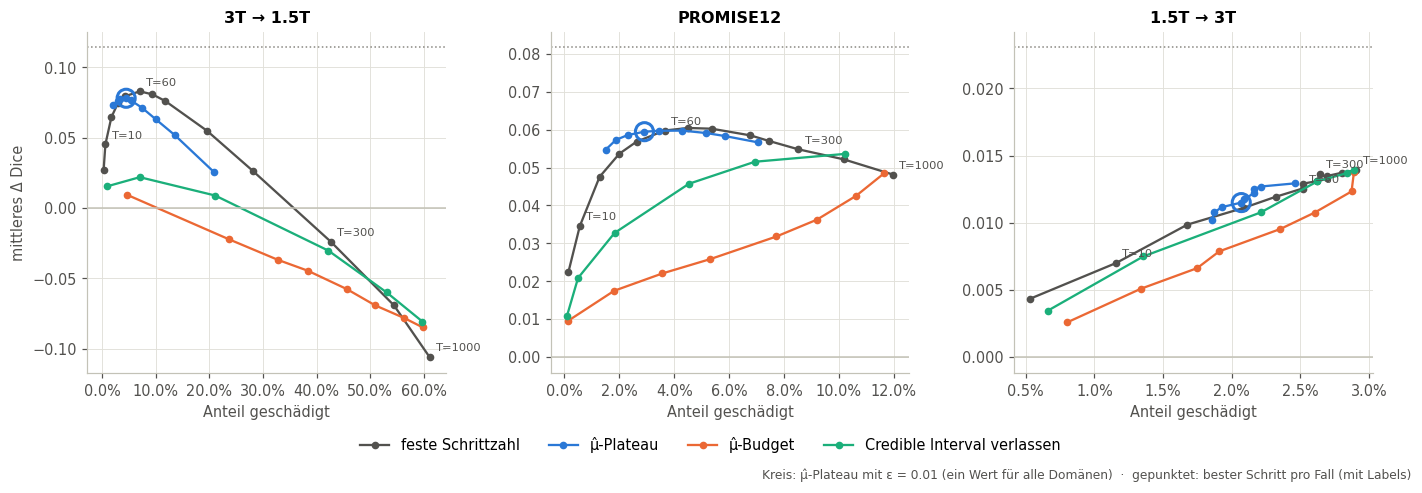

In [21]:
from scipy.stats import beta as Beta


def first_true(cond, default):
    return np.where(cond.any(1), cond.argmax(1), default)


def stop(x, rule, th):
    D, M = x["dice_per_step"], x["mu_per_step"]; last = D.shape[1] - 1
    if rule == "feste Schrittzahl": return np.full(len(D), min(th, last))
    if rule == "μ̂-Plateau":
        g = np.full(M.shape, np.inf); g[:, 10:] = M[:, 10:] - M[:, :-10]; return first_true(g < th, last)
    if rule == "μ̂-Budget": return first_true(M - M[:, :1] >= th, last)
    if rule == "Credible Interval verlassen":
        m0, k0 = np.clip(M[:, 0], 1e-4, 1 - 1e-4), x["kappa_before"]
        return first_true(M >= Beta.ppf(th, m0 * k0, (1 - m0) * k0)[:, None], last)


RULES = {"feste Schrittzahl": ([5, 10, 20, 30, 40, 60, 80, 100, 150, 200, 300, 500, 1000], "#52514e"),
         "μ̂-Plateau": ([0.03, 0.02, 0.015, 0.01, 0.0075, 0.005, 0.003, 0.002, 0.001], "#2a78d6"),
         "μ̂-Budget": ([0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3, 0.5], "#eb6834"),
         "Credible Interval verlassen": ([0.6, 0.7, 0.8, 0.9, 0.95, 0.99], "#1baf7a")}
rows = []
for rule, (grid, _) in RULES.items():
    for th in grid:
        for d, dl in DOMAINS.items():
            x = L[d]; s = stop(x, rule, th); D = x["dice_per_step"]
            delta = D[np.arange(len(D)), s] - D[:, 0]
            rows.append({"Regel": rule, "Parameter": th, "Domäne": dl, "ΔDice": delta.mean(),
                         "geschädigt": (delta < -TOL).mean(), "Stopp (Median)": np.median(s)})
SIM = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for rule, (_, c) in RULES.items():
        s = SIM[(SIM.Regel == rule) & (SIM.Domäne == dl)].sort_values("geschädigt")
        ax.plot(s["geschädigt"], s["ΔDice"], "-o", ms=4, lw=1.5, color=c, label=rule)
        if rule == "feste Schrittzahl":
            for _, q in s[s.Parameter.isin([10, 60, 300, 1000])].iterrows():
                ax.annotate(f"T={q.Parameter:g}", (q["geschädigt"], q["ΔDice"]), xytext=(4, 4),
                            textcoords="offset points", fontsize=7.5, color=c)
    p = SIM[(SIM.Regel == "μ̂-Plateau") & (SIM.Parameter == 0.01) & (SIM.Domäne == dl)].iloc[0]
    ax.scatter(p["geschädigt"], p["ΔDice"], s=140, facecolor="none", edgecolor=RULES["μ̂-Plateau"][1], lw=2, zorder=4)
    D = L[d]["dice_per_step"]; ax.axhline((D.max(1) - D[:, 0]).mean(), color=MUTED, ls=":", lw=1)
    ax.axhline(0, color=AXIS, lw=1); ax.set_title(dl); ax.set_xlabel("Anteil geschädigt")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=1))
axes[0].set_ylabel("mittleres Δ Dice")
fig.legend(handles=axes[0].get_lines()[:len(RULES)], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.07))
fig.text(0.99, -0.1, "Kreis: μ̂-Plateau mit ε = 0.01 (ein Wert für alle Domänen)  ·  gepunktet: bester Schritt pro Fall (mit Labels)",
         ha="right", fontsize=8, color=INK2)
plt.tight_layout(); show(fig, "08b_stopping_rules")

In [22]:
pick_ = {"feste Schrittzahl": 60, "μ̂-Plateau": 0.01}
tab = (SIM[SIM.apply(lambda r: pick_.get(r.Regel) == r.Parameter, axis=1)]
       .assign(Regel=lambda t: t.Regel + " (" + t.Parameter.map(lambda v: f"{v:g}") + ")")
       .pivot(index="Regel", columns="Domäne", values=["ΔDice", "geschädigt", "Stopp (Median)"])
       .reindex(columns=list(DOMAINS.values()), level=1))
opt = {dl: (L[d]["dice_per_step"].max(1) - L[d]["dice_per_step"][:, 0]).mean() for d, dl in DOMAINS.items()}
display(tab.style.format("{:+.3f}", subset=["ΔDice"]).format("{:.1%}", subset=["geschädigt"])
        .format("{:.0f}", subset=["Stopp (Median)"]))
print("Referenz bester Schritt pro Fall (mit Labels):", {k: round(v, 3) for k, v in opt.items()})

Referenz bester Schritt pro Fall (mit Labels): {'3T → 1.5T': 0.114, 'PROMISE12': 0.082, '1.5T → 3T': 0.023}


### 8.3 Wie sähe der Dice mit Early Stopping (μ̂-Plateau) aus?

Simulation auf den 1000-Schritt-Verläufen: Jeder Fall hält an, sobald sein μ̂ in den letzten
10 Schritten um weniger als 0.01 gestiegen ist (spätestens nach 1000 Schritten). Verglichen mit
dem, was wir bisher gemacht haben (feste 100 Schritte), mit „einfach lange laufen lassen“
(1000 Schritte) und mit der im Nachhinein besten festen Schrittzahl je Domäne.

**1. Dice über die Schritte.** Graue Kurve: mittlerer Dice, wenn *alle* Fälle nach t Schritten
anhalten (x-Achse logarithmisch). Blaue Linie: mittlerer Dice mit Early Stopping; die Raute sitzt
beim mittleren (Median-)Stopp-Schritt. Gestrichelt: ohne Adaption; gepunktet: bester Schritt pro
Fall (mit Labels).

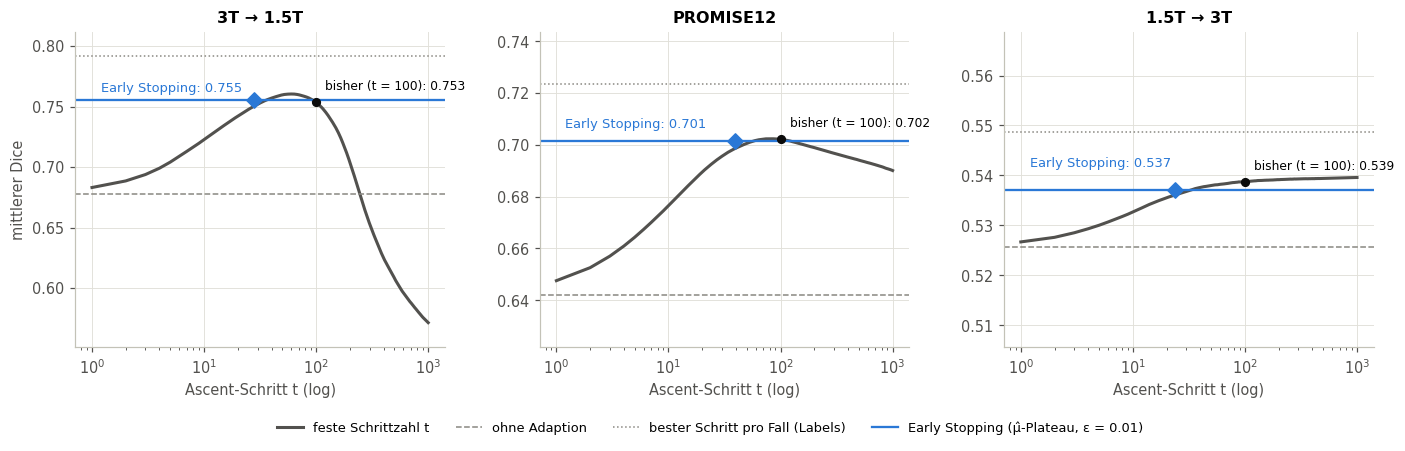

In [23]:
PLATEAU = 0.01
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    D = L[d]["dice_per_step"]; steps = np.arange(D.shape[1])
    curve = D.mean(0)
    st = stop(L[d], "μ̂-Plateau", PLATEAU); es = D[np.arange(len(D)), st].mean()
    ax.plot(steps[1:], curve[1:], color=COL["Threshold-Oracle"], label="feste Schrittzahl t")
    ax.axhline(curve[0], color=COL["Ausgang"], ls="--", lw=1, label="ohne Adaption")
    ax.axhline(D.max(1).mean(), color=MUTED, ls=":", lw=1, label="bester Schritt pro Fall (Labels)")
    ax.axhline(es, color=COL["pre-norm"], lw=1.5, label=f"Early Stopping (μ̂-Plateau, ε = {PLATEAU})")
    ax.scatter(np.median(st), es, marker="D", s=50, color=COL["pre-norm"], zorder=4)
    ax.scatter(100, curve[100], color=INK, s=25, zorder=4)
    ax.annotate(f"bisher (t = 100): {curve[100]:.3f}", (100, curve[100]), xytext=(6, 8),
                textcoords="offset points", fontsize=8)
    ax.text(1.2, es + 0.004, f"Early Stopping: {es:.3f}", color=COL["pre-norm"], fontsize=8.5, va="bottom")
    ax.set_xscale("log"); ax.set_title(dl); ax.set_xlabel("Ascent-Schritt t (log)")
    lo = min(curve.min(), curve[0]) - 0.02; ax.set_ylim(lo, D.max(1).mean() + 0.02)
axes[0].set_ylabel("mittlerer Dice")
fig.legend(handles=axes[0].get_lines(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), fontsize=8.5)
plt.tight_layout(); show(fig, "08c_dice_mit_early_stopping")

**2. Direkter Vergleich.** Mittlerer Dice der Testdomäne; die Zahl unten im Balken ist der Anteil
geschädigter Fälle (Dice mehr als 0.05 unter dem Start).

**Befund:** Im *Mittel* bringt Early Stopping praktisch denselben Dice wie unsere bisherigen festen
100 Schritte (0.755 / 0.701 / 0.537 vs. 0.753 / 0.702 / 0.539), aber mit weniger geschädigten Fällen
(4 / 3 / 2 % statt 12 / 5 / 3 %). Der eigentliche Vorteil zeigt sich, wenn man die Schrittzahl
falsch wählt: Mit 1000 Schritten fällt 3T → 1.5T auf 0.572, unter den Ausgangswert. Early Stopping
braucht keine Schrittzahl und kann deshalb nicht „zu lange“ laufen.

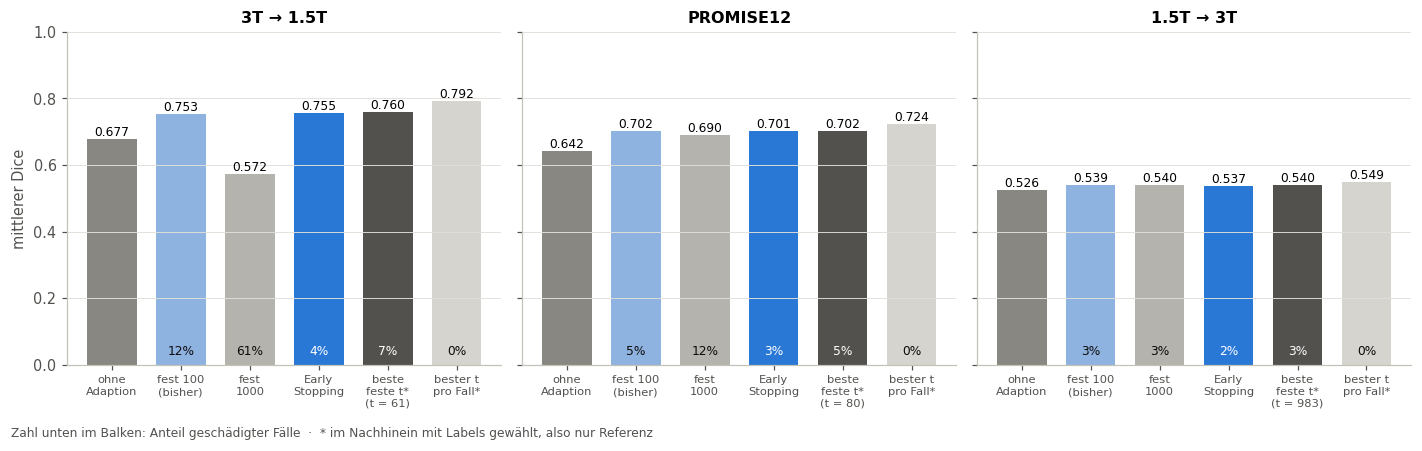

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
names = ["ohne\nAdaption", "fest 100\n(bisher)", "fest\n1000", "Early\nStopping", "beste\nfeste t*", "bester t\npro Fall*"]
cols = [COL["Ausgang"], "#8fb3e0", "#b5b3ad", COL["pre-norm"], COL["Threshold-Oracle"], "#d6d4ce"]
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    D = L[d]["dice_per_step"]; n = len(D); idx = np.arange(n); d0 = D[:, 0]
    t_best = int(D.mean(0).argmax())
    finals = [d0, D[:, 100], D[:, -1], D[idx, stop(L[d], "μ̂-Plateau", PLATEAU)], D[:, t_best], D.max(1)]
    for i, (f, c) in enumerate(zip(finals, cols)):
        ax.bar(i, f.mean(), color=c, width=0.72)
        ax.text(i, f.mean() + 0.01, f"{f.mean():.3f}", ha="center", fontsize=8)
        if i > 0:
            ax.text(i, 0.03, f"{(f < d0 - TOL).mean():.0%}", ha="center", fontsize=8,
                    color="white" if i in (3, 4) else INK)
    ax.set_xticks(range(len(names)), [n_.replace("feste t*", f"feste t*\n(t = {t_best})") for n_ in names], fontsize=7.5)
    ax.set_title(dl); ax.set_ylim(0, 1.0); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("mittlerer Dice")
fig.text(0.01, -0.03, "Zahl unten im Balken: Anteil geschädigter Fälle  ·  * im Nachhinein mit Labels gewählt, also nur Referenz",
         fontsize=8, color=INK2)
plt.tight_layout(); show(fig, "08d_vergleich_early_stopping")

**3. Wann hält die Regel an?** Verteilung der Stopp-Schritte über alle Fälle (x-Achse
logarithmisch). Die Regel wählt pro Fall einen eigenen Zeitpunkt; kein Fall läuft länger als
~280 Schritte, obwohl 1000 erlaubt wären. Der Balken ganz links ist Schritt 10, der früheste
mögliche Stopp (die Regel braucht 10 Schritte Vorlauf): Bei etwa einem Viertel der Fälle auf
3T → 1.5T und 1.5T → 3T steigt μ̂ von Anfang an kaum, diese Fälle werden praktisch gar nicht
adaptiert.

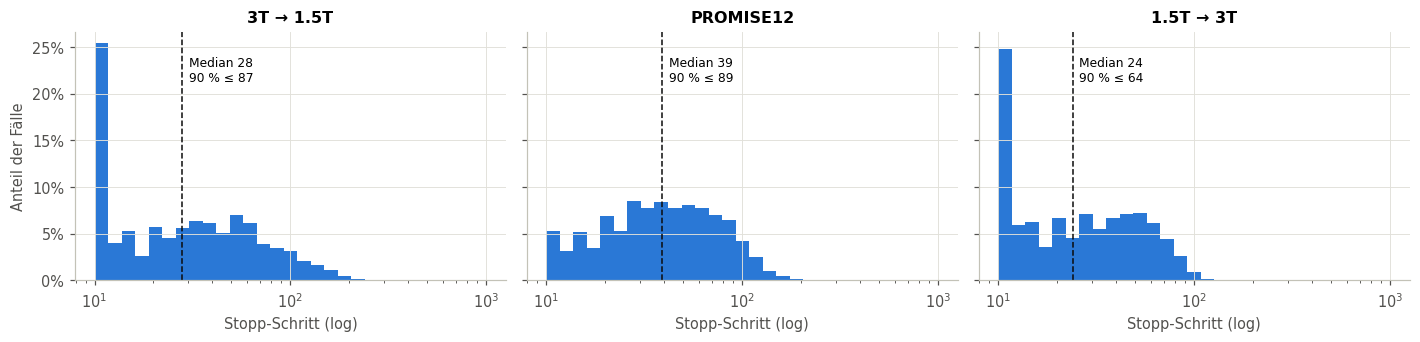

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
bins = np.logspace(np.log10(10), np.log10(1000), 30)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    st = stop(L[d], "μ̂-Plateau", PLATEAU)
    ax.hist(np.clip(st, 10, 1000), bins=bins, color=COL["pre-norm"], weights=np.full(len(st), 1 / len(st)))
    ax.axvline(np.median(st), color=INK, lw=1, ls="--")
    ax.text(np.median(st) * 1.08, ax.get_ylim()[1] * 0.9, f"Median {np.median(st):.0f}\n90 % ≤ {np.percentile(st, 90):.0f}",
            fontsize=8, va="top")
    ax.set_xscale("log"); ax.set_title(dl); ax.set_xlabel("Stopp-Schritt (log)")
    ax.yaxis.set_major_formatter(PCT)
axes[0].set_ylabel("Anteil der Fälle")
plt.tight_layout(); show(fig, "08e_stopp_schritte")

**Einordnung:** Die Plateau-Regel liegt im Bild *auf* der Kurve der festen Schrittzahlen, nicht
darüber; sie bringt nicht mehr Dice, aber man muss den Punkt auf der Kurve nicht pro Domäne
wählen. Bis zum besten Schritt pro Fall bleibt eine Lücke. Sie besteht vor allem aus Fällen, die
ab dem ersten Schritt schlechter werden (7.3); die kann keine Regel auf Basis von μ̂ erkennen.
Alle Ergebnisse in diesem Abschnitt sind Offline-Simulationen auf gespeicherten Verläufen.

## 9 · Anhang: zusätzliche Affine auf den Logits

**Aussage:** Eine zusätzliche Affine γ·z + β auf den U-Net-Logits (für ein 1-Kanal-Netz auf der
Maske dasselbe wie eine Schwellenverschiebung) ändert praktisch nichts, auch nicht beim
Soft-Dice-Oracle (|Δ Dice| ≤ 0.006).

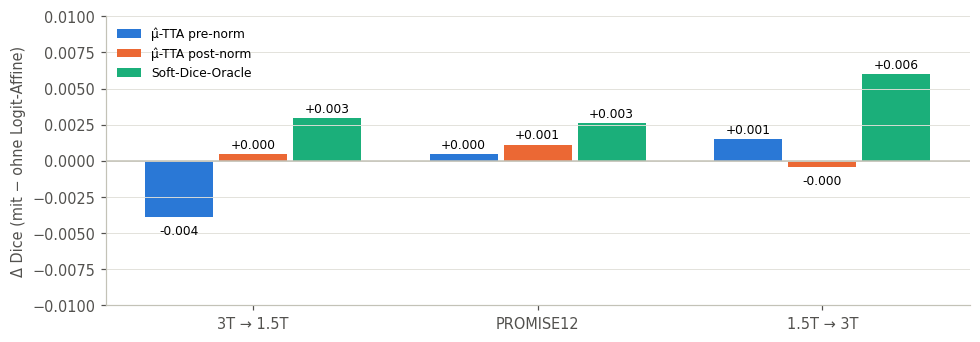

In [26]:
fig, ax = plt.subplots(figsize=(9, 3.2))
x = np.arange(len(DOMAINS))
for j, base in enumerate(MAIN):
    diff = [per_pred(base + " + Logits", d, lambda r: r["dice_after"].mean()).mean()
            - per_pred(base, d, lambda r: r["dice_after"].mean()).mean() for d in DOMAINS]
    ax.bar(x + (j - 1) * 0.26, diff, width=0.24, color=COL[base], label=LABEL[base])
    for xi, v in zip(x + (j - 1) * 0.26, diff):
        ax.text(xi, v + (0.0004 if v >= 0 else -0.0012), f"{v:+.3f}", ha="center", fontsize=8)
ax.axhline(0, color=AXIS, lw=1); ax.set_ylim(-0.01, 0.01)
ax.set_xticks(x, DOMAINS.values()); ax.set_ylabel("Δ Dice (mit − ohne Logit-Affine)")
ax.grid(axis="x", visible=False); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); show(fig, "09_logit_affine")